
# 10 — cross tier comparison

## Purpose

This notebook combines the **frozen Test outputs** from the dissertation's statistical, machine-learning and deep-learning tiers. It provides the final comparative evidence for:

- **RQ1:** accuracy differences across statistical, machine-learning and deep-learning approaches;
- **RQ2:** performance under random point missingness and 24-hour and 72-hour block gaps;
- **RQ3:** the contribution of neighbouring-station information within the ML and DL tiers;
- **RQ4:** the trade-off between Test accuracy and computational cost.

## Locked rules

This notebook:

- does **not** tune, refit or alter any model;
- uses Test predictions exactly as produced by Notebooks 06, 08 and 09c;
- independently reproduces MAE, RMSE, MedianAE and R² from row-level predictions;
- verifies identical Station–Datetime Test targets and ground truth across all models;
- retains predictions as generated, without post-hoc clipping;
- reports selection, final-fit and operational inference costs separately;
- standardises operational inference to **CPU** across all model families;
- retains model-family-appropriate devices for selection and final fitting/training;
- treats runtime as CPU-aligned operational evidence rather than a fully implementation-neutral measure of algorithmic complexity.

Run this notebook only after the frozen tier notebooks and their output audits have completed successfully.


## Interpretation rules

1. Cross-family accuracy comparisons use the untouched Test split only.
2. Spatial contribution is assessed within model families:
   - RF non-spatial versus RF spatio-temporal;
   - XGBoost non-spatial versus XGBoost spatio-temporal;
   - zero-neighbour BiGRU versus graph-enhanced BiGRU.
3. The ML feature sets were tuned separately under the same protocol and candidate budget.
4. The DL comparison is a stricter controlled ablation: initialisation, masking schedule, hyperparameters, parameter count and training duration were held constant.
5. Model-selection and final-fit costs are displayed separately because the model families used different, model-appropriate procedures and execution devices.
6. Operational inference is CPU-standardised using one effective worker or PyTorch thread. This improves hardware alignment at inference but does not make the cross-family implementations identical.


In [1]:
# ============================================================
# Step 1: Imports and locked comparison constants
# ============================================================

from __future__ import annotations

import hashlib
import json
import os
import platform
import sys
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 140)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

COMPARISON_VERSION = "cross_tier_comparison_v2_cpu_inference_2026-07-28"
EXPECTED_ML_PROTOCOL_VERSION = "shared_family_balanced_v1"
EXPECTED_DL_TUNING_PIPELINE = "dl_tuning_v5_results_path_2026-07-24"
# One documented rerun is required to replace the previous GPU-based
# DL operational-inference input with CPU-only frozen-model inference.
ALLOW_OVERWRITE_COMPLETED_COMPARISON = False
DOCUMENTED_RERUN_REASON = (
    "Replace the previous cross-tier runtime comparison with CPU-aligned "
    "operational inference across statistical, ML and DL models. Model "
    "selection, architecture, hyperparameters, evaluation targets and "
    "final-fit checkpoints remain unchanged. CPU and GPU execution may "
    "produce negligible floating-point differences in predictions, without "
    "materially changing accuracy results or model rankings."
)

if ALLOW_OVERWRITE_COMPLETED_COMPARISON:
    assert DOCUMENTED_RERUN_REASON.strip()

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

SCENARIO_LABELS = {
    "random10_point": "Random 10%",
    "random30_point": "Random 30%",
    "random50_point": "Random 50%",
    "block24_10percent": "Block 24h",
    "block72_10percent": "Block 72h",
}

SCENARIO_FAMILIES = {
    "random_point": [
        "random10_point",
        "random30_point",
        "random50_point",
    ],
    "block_gap": [
        "block24_10percent",
        "block72_10percent",
    ],
}

EXPECTED_TEST_TARGET_COUNTS = {
    "random10_point": 4318,
    "random30_point": 12954,
    "random50_point": 21590,
    "block24_10percent": 4392,
    "block72_10percent": 4536,
}
EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS = sum(
    EXPECTED_TEST_TARGET_COUNTS.values()
)

MODEL_METADATA = {
    "stat_station_mean": {
        "DisplayName": "Station train mean",
        "ShortLabel": "Train mean",
        "ModelFamily": "Statistical",
        "SpatialSetting": "Non-spatial",
    },
    "stat_linear_interpolation": {
        "DisplayName": "Linear interpolation",
        "ShortLabel": "Interpolation",
        "ModelFamily": "Statistical",
        "SpatialSetting": "Non-spatial",
    },
    "stat_kalman_arima": {
        "DisplayName": "Kalman-ARIMA",
        "ShortLabel": "Kalman-ARIMA",
        "ModelFamily": "Statistical",
        "SpatialSetting": "Non-spatial",
    },
    "ml_rf_non_spatial": {
        "DisplayName": "RF non-spatial",
        "ShortLabel": "RF non-spatial",
        "ModelFamily": "Machine Learning",
        "SpatialSetting": "Non-spatial",
    },
    "ml_rf_spatio_temporal": {
        "DisplayName": "RF spatio-temporal",
        "ShortLabel": "RF spatial",
        "ModelFamily": "Machine Learning",
        "SpatialSetting": "Spatio-temporal",
    },
    "ml_xgb_non_spatial": {
        "DisplayName": "XGBoost non-spatial",
        "ShortLabel": "XGB non-spatial",
        "ModelFamily": "Machine Learning",
        "SpatialSetting": "Non-spatial",
    },
    "ml_xgb_spatio_temporal": {
        "DisplayName": "XGBoost spatio-temporal",
        "ShortLabel": "XGB spatial",
        "ModelFamily": "Machine Learning",
        "SpatialSetting": "Spatio-temporal",
    },
    "dl_zero_neighbour": {
        "DisplayName": "BiGRU zero-neighbour control",
        "ShortLabel": "BiGRU zero",
        "ModelFamily": "Deep Learning",
        "SpatialSetting": "Non-spatial",
    },
    "dl_graph_enhanced": {
        "DisplayName": "Graph-enhanced BiGRU",
        "ShortLabel": "Graph BiGRU",
        "ModelFamily": "Deep Learning",
        "SpatialSetting": "Spatio-temporal",
    },
}

MODEL_ORDER = list(MODEL_METADATA)
PRIMARY_BLOCK72_MODELS = [
    "stat_kalman_arima",
    "ml_rf_spatio_temporal",
    "ml_xgb_spatio_temporal",
    "dl_graph_enhanced",
]
METRIC_COLUMNS = ["MAE", "RMSE", "MedianAE", "R2"]

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Platform:", platform.platform())
print("Expected total Test prediction targets per model:", EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS)

Python: 3.11.15
pandas: 3.0.5
NumPy: 2.4.6
Platform: Windows-10-10.0.19045-SP0
Expected total Test prediction targets per model: 47790


In [2]:
# ============================================================
# Step 2: Resolve repository paths and protect final outputs
# ============================================================

def find_codes_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        Path.home() / "Desktop" / "DISSERTATION" / "Codes",
    ]

    for candidate in candidates:
        candidate = candidate.resolve()

        if (
            (candidate / "data").exists()
            and (candidate / "notebooks").exists()
            and (candidate / "results").exists()
            and (candidate / "models").exists()
        ):
            return candidate

        if candidate.name.lower() == "notebooks" and (candidate.parent / "data").exists():
            return candidate.parent

    raise FileNotFoundError(
        "Could not locate the dissertation Codes root. Open this notebook "
        "from Codes/notebooks or update find_codes_root()."
    )


CODES_ROOT = find_codes_root()
DATA_MODELLING_DIR = CODES_ROOT / "data" / "modelling"
RESULTS_ROOT = CODES_ROOT / "results"

STAT_RESULTS_DIR = RESULTS_ROOT / "statistical_baselines"
ML_RESULTS_DIR = (
    RESULTS_ROOT
    / "machine_learning"
    / "final_evaluation"
    / EXPECTED_ML_PROTOCOL_VERSION
)
DL_RESULTS_ROOT = RESULTS_ROOT / "deep_learning"
DL_TUNING_DIR = (
    DL_RESULTS_ROOT
    / "08b_tuning"
    / EXPECTED_DL_TUNING_PIPELINE
    / "full"
)
DL_FINAL_DIR = DL_RESULTS_ROOT / "08c_final_evaluation"

OUTPUT_DIR = RESULTS_ROOT / "final_comparison" / "09_cross_tier"
FIGURE_DIR = OUTPUT_DIR / "figures"
FINAL_MANIFEST_PATH = OUTPUT_DIR / "cross_tier_comparison_manifest.json"

if FINAL_MANIFEST_PATH.exists():
    existing_manifest = json.loads(
        FINAL_MANIFEST_PATH.read_text(encoding="utf-8")
    )

    if existing_manifest.get("Status") == "comparison_complete":
        existing_runtime_protocol = existing_manifest.get(
            "RuntimeProtocol",
            {},
        )
        existing_cpu_controlled = bool(
            existing_runtime_protocol.get(
                "OperationalInferenceDeviceControlled",
                False,
            )
        ) and str(
            existing_runtime_protocol.get(
                "OperationalInferenceDevice",
                "",
            )
        ).lower() == "cpu"

        if not ALLOW_OVERWRITE_COMPLETED_COMPARISON:
            comparison_type = (
                "completed CPU-aligned comparison"
                if existing_cpu_controlled
                else "completed comparison"
            )
        
            raise RuntimeError(
                f"A {comparison_type} already exists. "
                "Set ALLOW_OVERWRITE_COMPLETED_COMPARISON=True only for "
                "a documented reproducibility rerun."
            )
        
        if not DOCUMENTED_RERUN_REASON.strip():
            raise RuntimeError(
                "A documented rerun reason is required before overwriting "
                "a completed comparison."
            )
        
        print("Documented rerun:", DOCUMENTED_RERUN_REASON)


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Codes root:", CODES_ROOT)
print("Statistical inputs:", STAT_RESULTS_DIR)
print("ML inputs:", ML_RESULTS_DIR)
print("DL tuning inputs:", DL_TUNING_DIR)
print("DL final inputs:", DL_FINAL_DIR)
print("Notebook 09 outputs:", OUTPUT_DIR)

Codes root: C:\Users\Msi\Desktop\DISSERTATION\Codes
Statistical inputs: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\statistical_baselines
ML inputs: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\final_evaluation\shared_family_balanced_v1
DL tuning inputs: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08b_tuning\dl_tuning_v5_results_path_2026-07-24\full
DL final inputs: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08c_final_evaluation
Notebook 09 outputs: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier


In [3]:
# ============================================================
# Step 3: Reusable audit, metric and write helpers
# ============================================================

def read_csv_required(path: Path, *, parse_dates: list[str] | None = None) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Required CSV not found: {path}")
    frame = pd.read_csv(path, parse_dates=parse_dates)
    if frame.empty:
        raise ValueError(f"Required CSV is empty: {path}")
    return frame


def read_json_required(path: Path) -> dict[str, Any]:
    if not path.exists():
        raise FileNotFoundError(f"Required JSON not found: {path}")
    return json.loads(path.read_text(encoding="utf-8"))


def atomic_write_dataframe(frame: pd.DataFrame, path: Path) -> None:
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temporary_path, index=False)
    os.replace(temporary_path, path)


def atomic_write_json(payload: dict[str, Any], path: Path) -> None:
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    temporary_path.write_text(
        json.dumps(payload, indent=2, default=str),
        encoding="utf-8",
    )
    os.replace(temporary_path, path)


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def calculate_regression_metrics(truth: np.ndarray, prediction: np.ndarray) -> dict[str, float | int]:
    truth = np.asarray(truth, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    if len(truth) == 0:
        raise ValueError("Cannot calculate metrics on an empty array.")
    if not (np.isfinite(truth).all() and np.isfinite(prediction).all()):
        raise ValueError("Metric inputs contain non-finite values.")

    error = prediction - truth
    absolute_error = np.abs(error)
    sse = float(np.sum(error ** 2))
    sst = float(np.sum((truth - np.mean(truth)) ** 2))

    return {
        "NTargets": int(len(truth)),
        "MAE": float(np.mean(absolute_error)),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MedianAE": float(np.median(absolute_error)),
        "R2": float(1.0 - sse / sst) if sst > 0 else np.nan,
    }


def attach_model_metadata(frame: pd.DataFrame) -> pd.DataFrame:
    output = frame.copy()
    for field in ["DisplayName", "ShortLabel", "ModelFamily", "SpatialSetting"]:
        output[field] = output["ModelID"].map(
            {model_id: metadata[field] for model_id, metadata in MODEL_METADATA.items()}
        )
    if output[["DisplayName", "ModelFamily", "SpatialSetting"]].isna().any().any():
        raise KeyError("At least one ModelID lacks dissertation-facing metadata.")
    return output


def normalise_statistical_model(value: str) -> str:
    key = str(value).strip().lower().replace("_", " ")
    key = " ".join(key.split())
    mapping = {
        "station train mean": "stat_station_mean",
        "station-level train mean": "stat_station_mean",
        "station mean": "stat_station_mean",
        "linear interpolation": "stat_linear_interpolation",
        "kalman-arima": "stat_kalman_arima",
        "kalman arima": "stat_kalman_arima",
    }
    if key not in mapping:
        raise KeyError(f"Unknown statistical model label: {value!r}")
    return mapping[key]


print("Helper functions defined.")

Helper functions defined.


In [4]:
# ============================================================
# Step 4: Audit frozen source manifests and required files
# ============================================================

STAT_PATHS = {
    "predictions_baselines": STAT_RESULTS_DIR / "statistical_baseline_predictions_mean_interpolation.csv",
    "predictions_kalman": STAT_RESULTS_DIR / "kalman_arima_predictions.csv",
    "accuracy_cost": STAT_RESULTS_DIR / "statistical_accuracy_cost_summary.csv",
    "runtime_summary": STAT_RESULTS_DIR / "statistical_runtime_summary.csv",
    "runtime_manifest": STAT_RESULTS_DIR / "statistical_runtime_manifest.json",
}

ML_PATHS = {
    "predictions": ML_RESULTS_DIR / "ml_final_test_predictions.csv",
    "metrics": ML_RESULTS_DIR / "ml_final_test_metrics.csv",
    "accuracy_cost": ML_RESULTS_DIR / "ml_accuracy_cost_summary.csv",
    "runtime_records": ML_RESULTS_DIR / "ml_final_runtime_records.csv",
    "runtime_summary": ML_RESULTS_DIR / "ml_final_runtime_summary.csv",
    "environment": ML_RESULTS_DIR / "computational_environment_final_evaluation.json",
    "manifest": ML_RESULTS_DIR / "ml_final_evaluation_manifest.json",
}

DL_PATHS = {
    "predictions": DL_FINAL_DIR / "dl_test_predictions.csv",
    "metrics": DL_FINAL_DIR / "dl_validation_test_metrics_by_scenario.csv",
    "runtime": DL_FINAL_DIR / "dl_final_runtime_and_resource_summary.csv",
    "inference_timing": DL_FINAL_DIR / "dl_inference_timing.csv",
    "spatial_delta": DL_FINAL_DIR / "dl_test_spatial_ablation_delta.csv",
    "representative_selection": DL_FINAL_DIR / "dl_representative_block72_selection.csv",
    "manifest": DL_FINAL_DIR / "dl_final_evaluation_manifest.json",
    "tuning_manifest": DL_TUNING_DIR / "dl_tuning_manifest.json",
}

BASE_DATA_PATH = DATA_MODELLING_DIR / "base_modelling_dataset_before_masking.csv"

required_paths = [*STAT_PATHS.values(), *ML_PATHS.values(), *DL_PATHS.values(), BASE_DATA_PATH]
for required_path in required_paths:
    if not required_path.exists():
        raise FileNotFoundError(f"Required frozen input is missing: {required_path}")

stat_manifest = read_json_required(STAT_PATHS["runtime_manifest"])
ml_manifest = read_json_required(ML_PATHS["manifest"])
ml_environment = read_json_required(ML_PATHS["environment"])
dl_manifest = read_json_required(DL_PATHS["manifest"])
dl_tuning_manifest = read_json_required(DL_PATHS["tuning_manifest"])

assert stat_manifest.get("Status") == "complete"
assert ml_manifest.get("Status") == "complete"
assert ml_manifest.get("TuningProtocolVersion") == EXPECTED_ML_PROTOCOL_VERSION
assert dl_manifest.get("Status") == "final_evaluation_complete"
assert dl_tuning_manifest.get("Status") == "full_validation_tuning_complete"
assert dl_tuning_manifest.get("TestDataUsedForSelection") is False
assert dl_manifest["DataProtocol"]["TestUsedForSelection"] is False

assert str(dl_manifest.get("InferenceDevice", "")).lower() == "cpu"
assert int(dl_manifest.get("CPUInferenceThreads", -1)) == 1

dl_inference_protocol = dl_manifest.get("InferenceProtocol", {})
assert str(dl_inference_protocol.get("Device", "")).lower() == "cpu"
assert int(dl_inference_protocol.get("CPUThreads", -1)) == 1
assert int(dl_inference_protocol.get("WarmupRuns", -1)) == 1
assert int(dl_inference_protocol.get("TimedRepeats", -1)) == 5
assert dl_inference_protocol.get("SummaryStatistic") == "median"
assert dl_inference_protocol.get("DiskLoadingIncluded") is False

source_file_audit_df = pd.DataFrame([
    {
        "SourceGroup": group_name,
        "LogicalName": logical_name,
        "Path": str(path),
        "Bytes": int(path.stat().st_size),
        "SHA256": file_sha256(path),
    }
    for group_name, path_map in [
        ("Statistical", STAT_PATHS),
        ("MachineLearning", ML_PATHS),
        ("DeepLearning", DL_PATHS),
    ]
    for logical_name, path in path_map.items()
])

atomic_write_dataframe(
    source_file_audit_df,
    OUTPUT_DIR / "cross_tier_source_file_audit.csv",
)
display(source_file_audit_df)
print("Frozen source-manifest and file audit passed.")

,SourceGroup,LogicalName,Path,Bytes,SHA256
0,Statistical,predictions_baselines,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,20226094,38f8ec3dcbd4e026fe7cf80bd26d1bda13bf8882d249e9...
1,Statistical,predictions_kalman,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,9790116,bf83e9a5cad893c336b879a8969d1ec05d96806d7724ca...
2,Statistical,accuracy_cost,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,3780,f1ced9ed80db5ef748e5c2880831c6f73f2785f0e0fa9d...
3,Statistical,runtime_summary,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,3939,e075591c8de0851fa64d9e04f3fb8580c6d602cd3399cf...
4,Statistical,runtime_manifest,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,2922,0fd33365586b1f7bfb980ad21cbc0b8f2de215075b61b1...
5,MachineLearning,predictions,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,37404781,3b419ec9ef4280380b3a3a3c1098826e3a7e9eb9d544d9...
6,MachineLearning,metrics,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,2961,0d040350ff2c232ea6492c50b340bf7fc19c0331ae6260...
7,MachineLearning,accuracy_cost,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,6014,97397dfdce953334843fc3453237c6c13b3858df3ceabd...
8,MachineLearning,runtime_records,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,20037,03e698507bd2653cab0eef1aae13e2a12469c2ba2bf25c...
9,MachineLearning,runtime_summary,C:\Users\Msi\Desktop\DISSERTATION\Codes\result...,10306,5ec0d3ce9c31098c02ca3b5b69cc7c341f78b7d7a0b32a...


Frozen source-manifest and file audit passed.


## Standardised model terminology

The dissertation-facing term **non-spatial** corresponds to:

- `temporal_only` in the ML outputs;
- `zero_neighbour` in the DL outputs.

Raw source labels are retained in the tier notebooks, while Notebook 10 adds consistent dissertation-facing names.

In [5]:
# ============================================================
# Step 5: Load and standardise all row-level Test predictions
# ============================================================

# Statistical predictions
stat_baseline_raw = read_csv_required(
    STAT_PATHS["predictions_baselines"],
    parse_dates=["Datetime"],
)
stat_kalman_raw = read_csv_required(
    STAT_PATHS["predictions_kalman"],
    parse_dates=["Datetime"],
)
stat_raw = pd.concat([stat_baseline_raw, stat_kalman_raw], ignore_index=True)
stat_raw = stat_raw.loc[stat_raw["Split"].eq("Test")].copy()
stat_raw["ModelID"] = stat_raw["Model"].map(normalise_statistical_model)
stat_predictions = stat_raw.rename(
    columns={"MaskingScenario": "Scenario", "PM25_original": "Truth"}
)[["ModelID", "Scenario", "Station", "Datetime", "Truth", "Prediction"]].copy()
stat_predictions["SourceTier"] = "Statistical"

# Machine-learning predictions
ml_model_map = {
    ("RandomForest", "temporal_only"): "ml_rf_non_spatial",
    ("RandomForest", "spatio_temporal"): "ml_rf_spatio_temporal",
    ("XGBoost", "temporal_only"): "ml_xgb_non_spatial",
    ("XGBoost", "spatio_temporal"): "ml_xgb_spatio_temporal",
}
ml_raw = read_csv_required(ML_PATHS["predictions"], parse_dates=["Datetime"])
if "Split" in ml_raw.columns:
    ml_raw = ml_raw.loc[ml_raw["Split"].eq("Test")].copy()
if "MaskingScenario" in ml_raw.columns and "Scenario" in ml_raw.columns:
    assert ml_raw["MaskingScenario"].astype(str).eq(ml_raw["Scenario"].astype(str)).all()
ml_raw["ModelID"] = [
    ml_model_map.get((model_name, feature_set))
    for model_name, feature_set in zip(ml_raw["Model"], ml_raw["FeatureSet"])
]
if ml_raw["ModelID"].isna().any():
    unknown = ml_raw.loc[ml_raw["ModelID"].isna(), ["Model", "FeatureSet"]].drop_duplicates()
    raise KeyError(f"Unknown ML model-feature labels:\n{unknown}")
ml_predictions = ml_raw.rename(columns={"PM25_original": "Truth"})[
    ["ModelID", "Scenario", "Station", "Datetime", "Truth", "Prediction"]
].copy()
ml_predictions["SourceTier"] = "Machine Learning"

# Deep-learning predictions
dl_model_map = {
    "zero_neighbour": "dl_zero_neighbour",
    "graph_enhanced": "dl_graph_enhanced",
}
dl_raw = read_csv_required(DL_PATHS["predictions"], parse_dates=["Datetime"])
if "Split" in dl_raw.columns:
    dl_raw = dl_raw.loc[dl_raw["Split"].eq("Test")].copy()
dl_raw["ModelID"] = dl_raw["ModelVariant"].map(dl_model_map)
if dl_raw["ModelID"].isna().any():
    raise KeyError("An unknown DL model variant was found.")
dl_predictions = dl_raw[
    ["ModelID", "Scenario", "Station", "Datetime", "Truth", "Prediction"]
].copy()
dl_predictions["SourceTier"] = "Deep Learning"

combined_predictions = pd.concat(
    [stat_predictions, ml_predictions, dl_predictions],
    ignore_index=True,
)
combined_predictions = attach_model_metadata(combined_predictions)
combined_predictions["Datetime"] = pd.to_datetime(combined_predictions["Datetime"])
combined_predictions["Truth"] = pd.to_numeric(combined_predictions["Truth"], errors="coerce")
combined_predictions["Prediction"] = pd.to_numeric(combined_predictions["Prediction"], errors="coerce")

if not (
    np.isfinite(combined_predictions["Truth"]).all()
    and np.isfinite(combined_predictions["Prediction"]).all()
):
    raise ValueError("Combined Test predictions contain non-finite values.")

print("Statistical prediction rows:", len(stat_predictions))
print("ML prediction rows:", len(ml_predictions))
print("DL prediction rows:", len(dl_predictions))
print("Combined prediction rows:", len(combined_predictions))
display(combined_predictions.head())

Statistical prediction rows: 143370
ML prediction rows: 191160
DL prediction rows: 95580
Combined prediction rows: 430110


,ModelID,Scenario,Station,Datetime,Truth,Prediction,SourceTier,DisplayName,ShortLabel,ModelFamily,SpatialSetting
0,stat_station_mean,random10_point,London Bexley,2025-01-02 01:00:00,4.906000,8.966961,Statistical,Station train mean,Train mean,Statistical,Non-spatial
1,stat_station_mean,random10_point,London Bexley,2025-01-02 09:00:00,5.943000,8.966961,Statistical,Station train mean,Train mean,Statistical,Non-spatial
2,stat_station_mean,random10_point,London Bexley,2025-01-02 14:00:00,4.434000,8.966961,Statistical,Station train mean,Train mean,Statistical,Non-spatial
3,stat_station_mean,random10_point,London Bexley,2025-01-03 10:00:00,5.094000,8.966961,Statistical,Station train mean,Train mean,Statistical,Non-spatial
4,stat_station_mean,random10_point,London Bexley,2025-01-03 21:00:00,14.906000,8.966961,Statistical,Station train mean,Train mean,Statistical,Non-spatial


In [6]:
# Save unified row-level Test predictions for downstream uncertainty analysis
unified_predictions_path = (
    OUTPUT_DIR / "cross_tier_unified_test_predictions.csv"
)

atomic_write_dataframe(
    combined_predictions[
        [
            "ModelID",
            "Scenario",
            "Station",
            "Datetime",
            "Prediction",
            "Truth",
        ]
    ],
    unified_predictions_path,
)

print(
    f"Saved: {unified_predictions_path}  "
    f"rows={len(combined_predictions):,}"
)

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\cross_tier_unified_test_predictions.csv  rows=430,110


In [7]:
# ============================================================
# Step 6: Audit identical Test target rows and ground truth
# ============================================================

duplicate_columns = ["ModelID", "Scenario", "Station", "Datetime"]
if combined_predictions.duplicated(duplicate_columns).any():
    raise RuntimeError("Duplicate model-scenario target predictions were found.")

expected_pairs = {(model_id, scenario) for model_id in MODEL_ORDER for scenario in SCENARIOS}
observed_pairs = set(
    combined_predictions[["ModelID", "Scenario"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)
assert observed_pairs == expected_pairs, "The expected 45 model-scenario combinations are incomplete."

target_audit_rows = []
reference_model_id = "stat_kalman_arima"

for scenario in SCENARIOS:
    expected_count = EXPECTED_TEST_TARGET_COUNTS[scenario]
    reference = (
        combined_predictions.loc[
            combined_predictions["ModelID"].eq(reference_model_id)
            & combined_predictions["Scenario"].eq(scenario),
            ["Station", "Datetime", "Truth"],
        ]
        .sort_values(["Station", "Datetime"])
        .reset_index(drop=True)
    )
    assert len(reference) == expected_count

    for model_id in MODEL_ORDER:
        candidate = (
            combined_predictions.loc[
                combined_predictions["ModelID"].eq(model_id)
                & combined_predictions["Scenario"].eq(scenario),
                ["Station", "Datetime", "Truth"],
            ]
            .sort_values(["Station", "Datetime"])
            .reset_index(drop=True)
        )

        keys_match = (
            len(candidate) == len(reference)
            and candidate[["Station", "Datetime"]].equals(reference[["Station", "Datetime"]])
        )
        truth_matches = (
            len(candidate) == len(reference)
            and np.allclose(
                candidate["Truth"].to_numpy(dtype=float),
                reference["Truth"].to_numpy(dtype=float),
                rtol=0.0,
                atol=1e-10,
            )
        )

        target_audit_rows.append({
            "ModelID": model_id,
            "Scenario": scenario,
            "NTargets": len(candidate),
            "ExpectedNTargets": expected_count,
            "KeysMatchReference": keys_match,
            "TruthMatchesReference": truth_matches,
        })

target_key_audit_df = pd.DataFrame(target_audit_rows)
assert target_key_audit_df["NTargets"].eq(target_key_audit_df["ExpectedNTargets"]).all()
assert target_key_audit_df["KeysMatchReference"].all()
assert target_key_audit_df["TruthMatchesReference"].all()

combined_predictions["Error"] = combined_predictions["Prediction"] - combined_predictions["Truth"]
combined_predictions["AbsoluteError"] = combined_predictions["Error"].abs()
combined_predictions["SquaredError"] = combined_predictions["Error"] ** 2

atomic_write_dataframe(
    target_key_audit_df,
    OUTPUT_DIR / "cross_tier_test_target_key_audit.csv",
)
print("Cross-tier target-row audit passed for all 45 model-scenario combinations.")
display(target_key_audit_df.head(15))

Cross-tier target-row audit passed for all 45 model-scenario combinations.


,ModelID,Scenario,NTargets,ExpectedNTargets,KeysMatchReference,TruthMatchesReference
0,stat_station_mean,random10_point,4318,4318,True,True
1,stat_linear_interpolation,random10_point,4318,4318,True,True
2,stat_kalman_arima,random10_point,4318,4318,True,True
3,ml_rf_non_spatial,random10_point,4318,4318,True,True
4,ml_rf_spatio_temporal,random10_point,4318,4318,True,True
5,ml_xgb_non_spatial,random10_point,4318,4318,True,True
6,ml_xgb_spatio_temporal,random10_point,4318,4318,True,True
7,dl_zero_neighbour,random10_point,4318,4318,True,True
8,dl_graph_enhanced,random10_point,4318,4318,True,True
9,stat_station_mean,random30_point,12954,12954,True,True


In [8]:
# ============================================================
# Step 7: Independently reproduce unified Test metrics
# ============================================================

metric_rows = []
for (model_id, scenario), group in combined_predictions.groupby(["ModelID", "Scenario"], sort=False):
    metrics = calculate_regression_metrics(
        group["Truth"].to_numpy(),
        group["Prediction"].to_numpy(),
    )
    metric_rows.append({"ModelID": model_id, "Scenario": scenario, **metrics})

unified_metrics_df = attach_model_metadata(pd.DataFrame(metric_rows))
unified_metrics_df["ModelOrder"] = unified_metrics_df["ModelID"].map(
    {model_id: index for index, model_id in enumerate(MODEL_ORDER)}
)
unified_metrics_df["ScenarioOrder"] = unified_metrics_df["Scenario"].map(
    {scenario: index for index, scenario in enumerate(SCENARIOS)}
)
unified_metrics_df = unified_metrics_df.sort_values(
    ["ModelOrder", "ScenarioOrder"]
).reset_index(drop=True)

assert len(unified_metrics_df) == 45
assert unified_metrics_df["NTargets"].eq(
    unified_metrics_df["Scenario"].map(EXPECTED_TEST_TARGET_COUNTS)
).all()

atomic_write_dataframe(
    unified_metrics_df.drop(columns=["ModelOrder", "ScenarioOrder"]),
    OUTPUT_DIR / "cross_tier_test_metrics.csv",
)

display(
    unified_metrics_df[
        ["DisplayName", "Scenario", "NTargets", "MAE", "RMSE", "MedianAE", "R2"]
    ]
)

,DisplayName,Scenario,NTargets,MAE,RMSE,MedianAE,R2
0,Station train mean,random10_point,4318,5.432958,8.337348,4.050986,0.017691
1,Station train mean,random30_point,12954,5.468418,8.405770,4.060961,0.013848
2,Station train mean,random50_point,21590,5.506791,8.490918,4.060961,0.012699
3,Station train mean,block24_10percent,4392,5.377014,8.087771,3.862986,0.015582
4,Station train mean,block72_10percent,4536,5.015728,7.917524,3.855964,0.062730
5,Linear interpolation,random10_point,4318,0.981857,1.791757,0.471500,0.954632
6,Linear interpolation,random30_point,12954,1.092046,1.969883,0.503333,0.945841
7,Linear interpolation,random50_point,21590,1.269088,2.245114,0.638000,0.930973
8,Linear interpolation,block24_10percent,4392,2.908681,4.772166,1.698540,0.657269
9,Linear interpolation,block72_10percent,4536,3.988088,6.327968,2.625562,0.401293


In [9]:
# ============================================================
# Step 8: Reconcile metrics with frozen tier outputs
# ============================================================

# Statistical source metrics
stat_source = read_csv_required(STAT_PATHS["accuracy_cost"])
stat_source["ModelID"] = stat_source["Model"].map(normalise_statistical_model)
if "NTargets" not in stat_source.columns:
    if "N_evaluated" in stat_source.columns:
        stat_source = stat_source.rename(columns={"N_evaluated": "NTargets"})
    elif "N" in stat_source.columns:
        stat_source = stat_source.rename(columns={"N": "NTargets"})
    else:
        raise KeyError("No target-count column found in statistical accuracy-cost output.")

# ML source metrics
ml_source = read_csv_required(ML_PATHS["metrics"])
if "Split" in ml_source.columns:
    ml_source = ml_source.loc[ml_source["Split"].eq("Test")].copy()
ml_source["ModelID"] = [
    ml_model_map.get((model_name, feature_set))
    for model_name, feature_set in zip(ml_source["Model"], ml_source["FeatureSet"])
]

# DL source metrics
dl_source = read_csv_required(DL_PATHS["metrics"])
dl_source = dl_source.loc[dl_source["Split"].eq("Test")].copy()
dl_source["ModelID"] = dl_source["ModelVariant"].map(dl_model_map)

source_metrics_df = pd.concat([
    stat_source[["ModelID", "Scenario", "NTargets", *METRIC_COLUMNS]],
    ml_source[["ModelID", "Scenario", "NTargets", *METRIC_COLUMNS]],
    dl_source[["ModelID", "Scenario", "NTargets", *METRIC_COLUMNS]],
], ignore_index=True)

source_metric_audit_df = unified_metrics_df[
    ["ModelID", "Scenario", "NTargets", *METRIC_COLUMNS]
].merge(
    source_metrics_df,
    on=["ModelID", "Scenario"],
    how="outer",
    suffixes=("_Reproduced", "_Source"),
    validate="one_to_one",
)

source_metric_audit_df["TargetCountMatches"] = (
    source_metric_audit_df["NTargets_Reproduced"]
    == source_metric_audit_df["NTargets_Source"]
)
assert source_metric_audit_df["TargetCountMatches"].all()

for metric in METRIC_COLUMNS:
    difference_column = f"{metric}AbsoluteDifference"
    source_metric_audit_df[difference_column] = (
        source_metric_audit_df[f"{metric}_Reproduced"]
        - source_metric_audit_df[f"{metric}_Source"]
    ).abs()
    assert np.allclose(
        source_metric_audit_df[f"{metric}_Reproduced"],
        source_metric_audit_df[f"{metric}_Source"],
        rtol=1e-5,
        atol=1e-8,
        equal_nan=True,
    ), f"Reproduced {metric} differs from a frozen source output."

source_metric_audit_df["AllMetricsReproduced"] = True
atomic_write_dataframe(
    source_metric_audit_df,
    OUTPUT_DIR / "cross_tier_metric_reproduction_audit.csv",
)
print("All 45 source metric rows were reproduced from row-level Test predictions.")

All 45 source metric rows were reproduced from row-level Test predictions.


In [10]:
# ============================================================
# Step 9: Family-balanced metrics, scenario ranks and winners
# ============================================================

family_rows = []
for model_id in MODEL_ORDER:
    model_metrics = unified_metrics_df.loc[
        unified_metrics_df["ModelID"].eq(model_id)
    ].set_index("Scenario")
    random_metrics = model_metrics.loc[SCENARIO_FAMILIES["random_point"]]
    block_metrics = model_metrics.loc[SCENARIO_FAMILIES["block_gap"]]

    row = {"ModelID": model_id}
    for metric in ["MAE", "RMSE", "MedianAE"]:
        random_macro = float(random_metrics[metric].mean())
        block_macro = float(block_metrics[metric].mean())
        row[f"RandomMacro{metric}"] = random_macro
        row[f"BlockMacro{metric}"] = block_macro
        row[f"FamilyBalanced{metric}"] = 0.5 * random_macro + 0.5 * block_macro
    row["MeanScenarioR2"] = float(model_metrics["R2"].mean())
    family_rows.append(row)

family_metrics_df = attach_model_metadata(pd.DataFrame(family_rows))
family_metrics_df["FamilyBalancedMAERank"] = family_metrics_df["FamilyBalancedMAE"].rank(
    method="min", ascending=True
).astype(int)
family_metrics_df = family_metrics_df.sort_values(
    ["FamilyBalancedMAE", "ModelID"]
).reset_index(drop=True)

scenario_rankings_df = unified_metrics_df[
    ["ModelID", "DisplayName", "ModelFamily", "Scenario", "MAE", "RMSE", "MedianAE", "R2"]
].copy()
scenario_rankings_df["ScenarioMAERank"] = scenario_rankings_df.groupby("Scenario")["MAE"].rank(
    method="min", ascending=True
).astype(int)
scenario_rankings_df = scenario_rankings_df.sort_values(
    ["Scenario", "ScenarioMAERank", "MAE"]
).reset_index(drop=True)

winner_rows = []
for scenario in SCENARIOS:
    scenario_df = scenario_rankings_df.loc[
        scenario_rankings_df["Scenario"].eq(scenario)
    ].sort_values(["ScenarioMAERank", "MAE"])
    winner = scenario_df.iloc[0]
    winner_rows.append({
        "Scenario": scenario,
        "ScenarioLabel": SCENARIO_LABELS[scenario],
        "WinningModelID": winner["ModelID"],
        "WinningModel": winner["DisplayName"],
        "WinningMAE": float(winner["MAE"]),
        "SecondBestMAE": float(scenario_df.iloc[1]["MAE"]),
        "WinningMarginMAE": float(scenario_df.iloc[1]["MAE"] - winner["MAE"]),
        "MedianModelMAE": float(scenario_df["MAE"].median()),
        "MeanModelMAE": float(scenario_df["MAE"].mean()),
    })
scenario_winners_df = pd.DataFrame(winner_rows)
scenario_difficulty_df = scenario_winners_df[
    ["Scenario", "ScenarioLabel", "MedianModelMAE", "MeanModelMAE"]
].sort_values("MedianModelMAE").reset_index(drop=True)
scenario_difficulty_df["DifficultyRankByMedianMAE"] = np.arange(1, len(scenario_difficulty_df) + 1)

atomic_write_dataframe(family_metrics_df, OUTPUT_DIR / "cross_tier_family_balanced_metrics.csv")
atomic_write_dataframe(scenario_rankings_df, OUTPUT_DIR / "cross_tier_scenario_rankings.csv")
atomic_write_dataframe(scenario_winners_df, OUTPUT_DIR / "cross_tier_scenario_winners.csv")
atomic_write_dataframe(
    scenario_difficulty_df,
    OUTPUT_DIR / "cross_tier_scenario_difficulty_summary.csv",
)

print("Family-balanced Test ranking:")
display(
    family_metrics_df[
        [
            "FamilyBalancedMAERank",
            "DisplayName",
            "RandomMacroMAE",
            "BlockMacroMAE",
            "FamilyBalancedMAE",
            "FamilyBalancedRMSE",
        ]
    ]
)
print("Scenario winners:")
display(scenario_winners_df)

Family-balanced Test ranking:


,FamilyBalancedMAERank,DisplayName,RandomMacroMAE,BlockMacroMAE,FamilyBalancedMAE,FamilyBalancedRMSE
0,1,Graph-enhanced BiGRU,1.114907,1.676465,1.395686,2.318186
1,2,Linear interpolation,1.114330,3.448385,2.281357,3.776159
2,3,Kalman-ARIMA,1.076847,3.530271,2.303559,3.816298
3,4,BiGRU zero-neighbour control,1.336163,3.314209,2.325186,3.864819
4,5,XGBoost spatio-temporal,1.623623,3.406192,2.514908,4.377868
5,6,RF spatio-temporal,1.652546,3.637429,2.644987,4.652193
6,7,XGBoost non-spatial,1.528229,4.501234,3.014731,5.398739
7,8,RF non-spatial,1.787691,4.602072,3.194881,5.537410
8,9,Station train mean,5.469389,5.196371,5.332880,8.206996


Scenario winners:


,Scenario,ScenarioLabel,WinningModelID,WinningModel,WinningMAE,SecondBestMAE,WinningMarginMAE,MedianModelMAE,MeanModelMAE
0,random10_point,Random 10%,stat_kalman_arima,Kalman-ARIMA,0.939781,0.976043,0.036262,1.102477,1.565725
1,random30_point,Random 30%,stat_kalman_arima,Kalman-ARIMA,1.056700,1.092046,0.035347,1.498023,1.827815
2,random50_point,Random 50%,stat_kalman_arima,Kalman-ARIMA,1.234060,1.260425,0.026365,1.984187,2.174369
3,block24_10percent,Block 24h,dl_graph_enhanced,Graph-enhanced BiGRU,1.624898,2.796927,1.172029,3.267838,3.426059
4,block72_10percent,Block 72h,dl_graph_enhanced,Graph-enhanced BiGRU,1.728032,3.544546,1.816514,3.988088,3.976747


## RQ1 and RQ2: Accuracy across model families and missingness scenarios

The Test MAE heatmap provides a common view of all nine frozen configurations. Exact MAE, RMSE, MedianAE and R² values remain available in the accompanying CSV tables.

The family-balanced summary gives equal descriptive weight to the random-point and block-gap families. It is not used for further tuning.

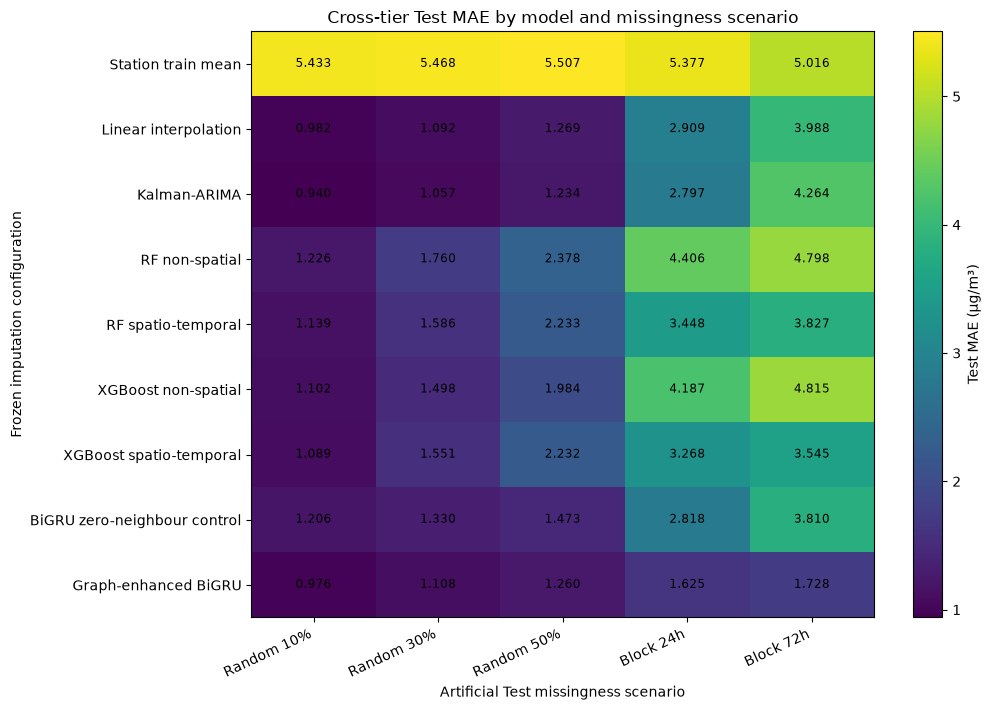

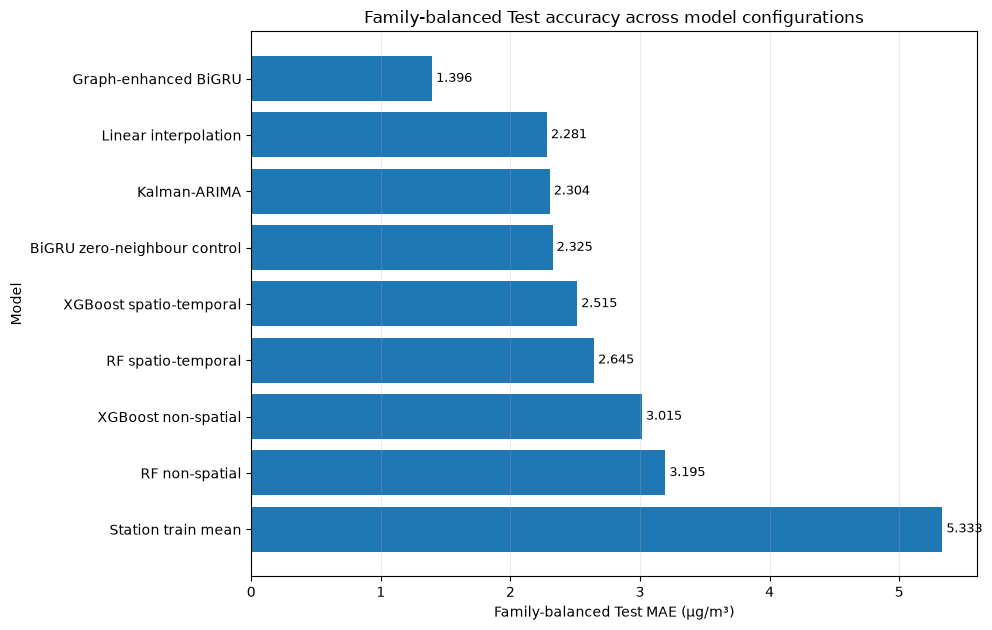

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_test_mae_heatmap.png
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_family_balanced_mae.png


In [11]:
# ============================================================
# Step 10: Main RQ1/RQ2 figures
# ============================================================

mae_matrix = unified_metrics_df.pivot(
    index="ModelID",
    columns="Scenario",
    values="MAE",
).reindex(index=MODEL_ORDER, columns=SCENARIOS)

fig, ax = plt.subplots(figsize=(10.5, 7.2))
image = ax.imshow(mae_matrix.to_numpy(), aspect="auto")
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Test MAE (µg/m³)")
ax.set_xticks(
    np.arange(len(SCENARIOS)),
    labels=[SCENARIO_LABELS[scenario] for scenario in SCENARIOS],
    rotation=25,
    ha="right",
)
ax.set_yticks(
    np.arange(len(MODEL_ORDER)),
    labels=[MODEL_METADATA[model_id]["DisplayName"] for model_id in MODEL_ORDER],
)

for row_index in range(len(MODEL_ORDER)):
    for column_index in range(len(SCENARIOS)):
        cell_value = float(mae_matrix.iloc[row_index, column_index])
        ax.text(
            column_index,
            row_index,
            f"{cell_value:.3f}",
            ha="center",
            va="center",
            fontsize=8.5,
        )

ax.set_xlabel("Artificial Test missingness scenario")
ax.set_ylabel("Frozen imputation configuration")
ax.set_title("Cross-tier Test MAE by model and missingness scenario")
fig.tight_layout()
mae_heatmap_path = FIGURE_DIR / "cross_tier_test_mae_heatmap.png"
fig.savefig(mae_heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

family_plot_df = family_metrics_df.sort_values("FamilyBalancedMAE", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6.4))
ax.barh(family_plot_df["DisplayName"], family_plot_df["FamilyBalancedMAE"])
ax.invert_yaxis()
ax.set_xlabel("Family-balanced Test MAE (µg/m³)")
ax.set_ylabel("Model")
ax.set_title("Family-balanced Test accuracy across model configurations")
ax.grid(axis="x", alpha=0.25)
for row_index, value in enumerate(family_plot_df["FamilyBalancedMAE"]):
    ax.text(float(value), row_index, f" {value:.3f}", va="center", fontsize=9)
fig.tight_layout()
family_bar_path = FIGURE_DIR / "cross_tier_family_balanced_mae.png"
fig.savefig(family_bar_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", mae_heatmap_path)
print("Saved:", family_bar_path)

## RQ3: Contribution of neighbouring-station information

Spatial gain is defined as:

\[
\Delta MAE = MAE_{\text{non-spatial}} - MAE_{\text{spatio-temporal}}
\]

A positive value indicates improved Test accuracy after incorporating neighbouring-station information. The output records whether each comparison is a separately tuned ML feature-set comparison or the stricter controlled DL ablation.

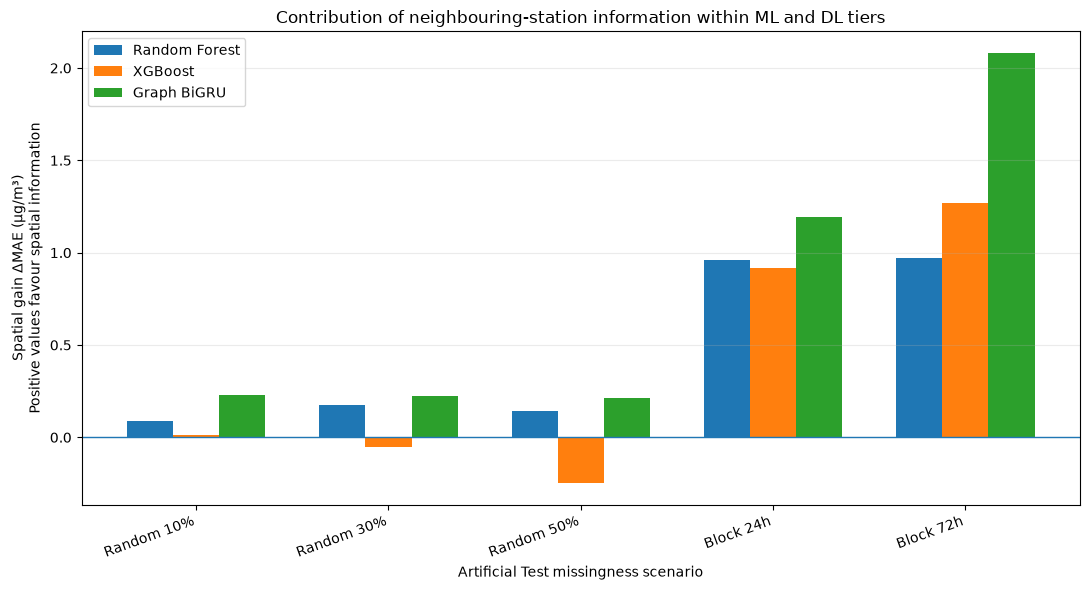

,ComparisonID,ComparisonLabel,NonSpatialModelID,SpatialModelID,ComparisonType,Scenario,ScenarioLabel,NTargets,NonSpatialMAE,SpatioTemporalMAE,DeltaMAE_NonSpatialMinusSpatial,RelativeMAEImprovementPercent,DeltaRMSE_NonSpatialMinusSpatial,DeltaR2_SpatialMinusNonSpatial
0,RandomForest,Random Forest,ml_rf_non_spatial,ml_rf_spatio_temporal,Separately tuned feature-set comparison,random10_point,Random 10%,4318,1.225580,1.138710,0.086870,7.088035,0.154401,0.008660
1,RandomForest,Random Forest,ml_rf_non_spatial,ml_rf_spatio_temporal,Separately tuned feature-set comparison,random30_point,Random 30%,12954,1.759943,1.586224,0.173719,9.870697,0.345848,0.030546
2,RandomForest,Random Forest,ml_rf_non_spatial,ml_rf_spatio_temporal,Separately tuned feature-set comparison,random50_point,Random 50%,21590,2.377549,2.232703,0.144846,6.092253,0.233580,0.028360
3,RandomForest,Random Forest,ml_rf_non_spatial,ml_rf_spatio_temporal,Separately tuned feature-set comparison,block24_10percent,Block 24h,4392,4.405791,3.447944,0.957848,21.740649,1.653653,0.329859
4,RandomForest,Random Forest,ml_rf_non_spatial,ml_rf_spatio_temporal,Separately tuned feature-set comparison,block72_10percent,Block 72h,4536,4.798352,3.826914,0.971439,20.245259,1.397996,0.307859
5,XGBoost,XGBoost,ml_xgb_non_spatial,ml_xgb_spatio_temporal,Separately tuned feature-set comparison,random10_point,Random 10%,4318,1.102477,1.088503,0.013974,1.267530,0.028190,0.001526
6,XGBoost,XGBoost,ml_xgb_non_spatial,ml_xgb_spatio_temporal,Separately tuned feature-set comparison,random30_point,Random 30%,12954,1.498023,1.550808,-0.052785,-3.523677,-0.090993,-0.007824
7,XGBoost,XGBoost,ml_xgb_non_spatial,ml_xgb_spatio_temporal,Separately tuned feature-set comparison,random50_point,Random 50%,21590,1.984187,2.231558,-0.247372,-12.467152,-0.315067,-0.036403
8,XGBoost,XGBoost,ml_xgb_non_spatial,ml_xgb_spatio_temporal,Separately tuned feature-set comparison,block24_10percent,Block 24h,4392,4.187147,3.267838,0.919309,21.955503,2.046584,0.387756
9,XGBoost,XGBoost,ml_xgb_non_spatial,ml_xgb_spatio_temporal,Separately tuned feature-set comparison,block72_10percent,Block 72h,4536,4.815321,3.544546,1.270775,26.390239,2.288813,0.487043


,ComparisonID,ComparisonLabel,ComparisonType,RandomMacroDeltaMAE,BlockMacroDeltaMAE,FamilyBalancedDeltaMAE,ScenariosImproved,ScenariosWorsened
0,RandomForest,Random Forest,Separately tuned feature-set comparison,0.135145,0.964643,0.549894,5,0
1,XGBoost,XGBoost,Separately tuned feature-set comparison,-0.095394,1.095042,0.499824,3,2
2,DeepLearning,Graph BiGRU,Controlled zero-neighbour ablation,0.221256,1.637744,0.929500,5,0


Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_spatial_gain_delta_mae.png


In [12]:
# ============================================================
# Step 11: Unified ML and DL spatial-gain analysis
# ============================================================

spatial_pairs = [
    {
        "ComparisonID": "RandomForest",
        "ComparisonLabel": "Random Forest",
        "NonSpatialModelID": "ml_rf_non_spatial",
        "SpatialModelID": "ml_rf_spatio_temporal",
        "ComparisonType": "Separately tuned feature-set comparison",
    },
    {
        "ComparisonID": "XGBoost",
        "ComparisonLabel": "XGBoost",
        "NonSpatialModelID": "ml_xgb_non_spatial",
        "SpatialModelID": "ml_xgb_spatio_temporal",
        "ComparisonType": "Separately tuned feature-set comparison",
    },
    {
        "ComparisonID": "DeepLearning",
        "ComparisonLabel": "Graph BiGRU",
        "NonSpatialModelID": "dl_zero_neighbour",
        "SpatialModelID": "dl_graph_enhanced",
        "ComparisonType": "Controlled zero-neighbour ablation",
    },
]

metric_lookup = unified_metrics_df.set_index(["ModelID", "Scenario"])
spatial_gain_rows = []

for pair in spatial_pairs:
    for scenario in SCENARIOS:
        non_spatial = metric_lookup.loc[(pair["NonSpatialModelID"], scenario)]
        spatial = metric_lookup.loc[(pair["SpatialModelID"], scenario)]
        assert int(non_spatial["NTargets"]) == int(spatial["NTargets"])
        delta_mae = float(non_spatial["MAE"] - spatial["MAE"])
        spatial_gain_rows.append({
            **pair,
            "Scenario": scenario,
            "ScenarioLabel": SCENARIO_LABELS[scenario],
            "NTargets": int(spatial["NTargets"]),
            "NonSpatialMAE": float(non_spatial["MAE"]),
            "SpatioTemporalMAE": float(spatial["MAE"]),
            "DeltaMAE_NonSpatialMinusSpatial": delta_mae,
            "RelativeMAEImprovementPercent": float(100.0 * delta_mae / non_spatial["MAE"]),
            "DeltaRMSE_NonSpatialMinusSpatial": float(non_spatial["RMSE"] - spatial["RMSE"]),
            "DeltaR2_SpatialMinusNonSpatial": float(spatial["R2"] - non_spatial["R2"]),
        })

spatial_gain_df = pd.DataFrame(spatial_gain_rows)
family_spatial_gain_rows = []

for (comparison_id, comparison_label, comparison_type), group in spatial_gain_df.groupby(
    ["ComparisonID", "ComparisonLabel", "ComparisonType"], sort=False
):
    random_group = group.loc[group["Scenario"].isin(SCENARIO_FAMILIES["random_point"])]
    block_group = group.loc[group["Scenario"].isin(SCENARIO_FAMILIES["block_gap"])]
    random_delta = float(random_group["DeltaMAE_NonSpatialMinusSpatial"].mean())
    block_delta = float(block_group["DeltaMAE_NonSpatialMinusSpatial"].mean())
    family_spatial_gain_rows.append({
        "ComparisonID": comparison_id,
        "ComparisonLabel": comparison_label,
        "ComparisonType": comparison_type,
        "RandomMacroDeltaMAE": random_delta,
        "BlockMacroDeltaMAE": block_delta,
        "FamilyBalancedDeltaMAE": 0.5 * random_delta + 0.5 * block_delta,
        "ScenariosImproved": int((group["DeltaMAE_NonSpatialMinusSpatial"] > 0).sum()),
        "ScenariosWorsened": int((group["DeltaMAE_NonSpatialMinusSpatial"] < 0).sum()),
    })

family_spatial_gain_df = pd.DataFrame(family_spatial_gain_rows)
atomic_write_dataframe(
    spatial_gain_df,
    OUTPUT_DIR / "cross_tier_spatial_gain_by_scenario.csv",
)
atomic_write_dataframe(
    family_spatial_gain_df,
    OUTPUT_DIR / "cross_tier_spatial_gain_by_family.csv",
)

fig, ax = plt.subplots(figsize=(11, 6))
x_positions = np.arange(len(SCENARIOS))
bar_width = 0.24

for pair_index, pair in enumerate(spatial_pairs):
    pair_df = spatial_gain_df.loc[
        spatial_gain_df["ComparisonID"].eq(pair["ComparisonID"])
    ].set_index("Scenario").reindex(SCENARIOS)
    offset = (pair_index - (len(spatial_pairs) - 1) / 2) * bar_width
    ax.bar(
        x_positions + offset,
        pair_df["DeltaMAE_NonSpatialMinusSpatial"],
        width=bar_width,
        label=pair["ComparisonLabel"],
    )

ax.axhline(0.0, linewidth=1.0)
ax.set_xticks(
    x_positions,
    labels=[SCENARIO_LABELS[scenario] for scenario in SCENARIOS],
    rotation=20,
    ha="right",
)
ax.set_xlabel("Artificial Test missingness scenario")
ax.set_ylabel("Spatial gain ΔMAE (µg/m³)\nPositive values favour spatial information")
ax.set_title("Contribution of neighbouring-station information within ML and DL tiers")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
spatial_gain_plot_path = FIGURE_DIR / "cross_tier_spatial_gain_delta_mae.png"
fig.savefig(spatial_gain_plot_path, dpi=300, bbox_inches="tight")
plt.show()

display(spatial_gain_df)
display(family_spatial_gain_df)
print("Saved:", spatial_gain_plot_path)

## Long-gap behaviour

The 72-hour position analysis uses identical Test blocks for Kalman-ARIMA, the two spatio-temporal tree models and the graph-enhanced BiGRU. Block positions are reconstructed from the shared Station–Datetime target keys rather than imported from tier-specific diagnostic tables.

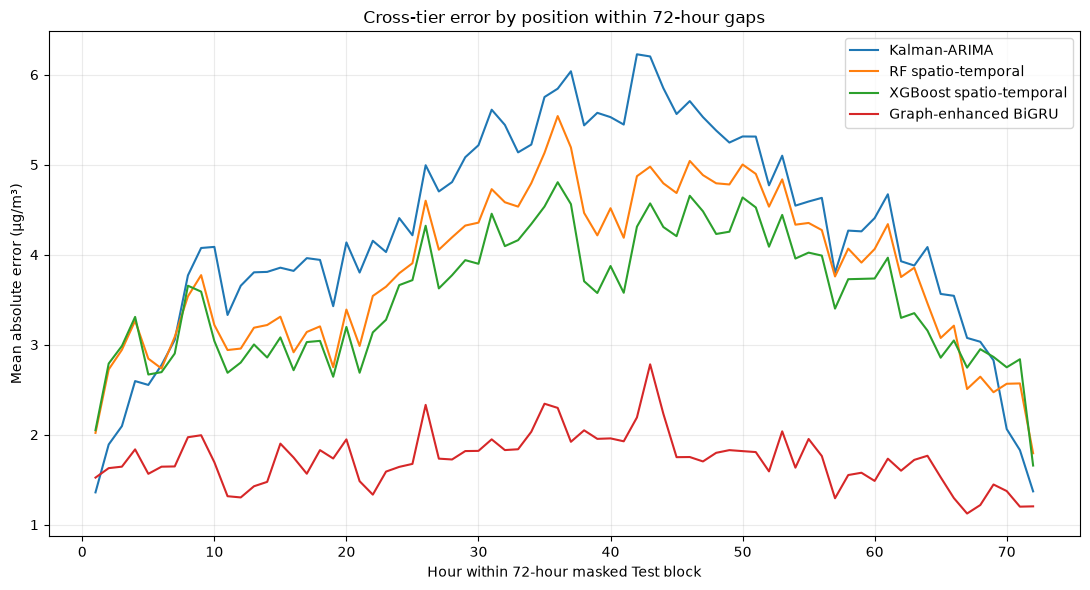

,ModelID,DisplayName,EdgeMAE,MiddleMAE,MiddleMinusEdgeMAE,MiddleToEdgeRatio
0,dl_graph_enhanced,Graph-enhanced BiGRU,1.389178,2.024275,0.635096,1.457174
1,ml_rf_spatio_temporal,RF spatio-temporal,2.277172,4.729410,2.452238,2.076879
2,ml_xgb_spatio_temporal,XGBoost spatio-temporal,2.334073,4.166013,1.831941,1.784869
3,stat_kalman_arima,Kalman-ARIMA,1.612491,5.604573,3.992082,3.475724


Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_block72_position_mae.png


In [13]:
# ============================================================
# Step 12: Cross-tier 72-hour gap-position profile
# ============================================================

block_scenario = "block72_10percent"
reference_block_keys = (
    combined_predictions.loc[
        combined_predictions["ModelID"].eq("dl_graph_enhanced")
        & combined_predictions["Scenario"].eq(block_scenario),
        ["Station", "Datetime"],
    ]
    .drop_duplicates()
    .sort_values(["Station", "Datetime"])
    .reset_index(drop=True)
)

time_difference = reference_block_keys.groupby("Station")["Datetime"].diff()
reference_block_keys["NewBlock"] = time_difference.ne(pd.Timedelta(hours=1)) | time_difference.isna()
reference_block_keys["BlockNumber"] = reference_block_keys.groupby("Station")["NewBlock"].cumsum().astype(int)
reference_block_keys["PositionInBlock"] = (
    reference_block_keys.groupby(["Station", "BlockNumber"]).cumcount() + 1
)

block_metadata = reference_block_keys.groupby(["Station", "BlockNumber"]).agg(
    BlockStart=("Datetime", "min"),
    BlockEnd=("Datetime", "max"),
    BlockLength=("Datetime", "size"),
).reset_index()
assert set(block_metadata["BlockLength"].unique()) == {72}
block_metadata["BlockID"] = (
    block_metadata["Station"].str.replace(" ", "_", regex=False)
    + "__"
    + block_metadata["BlockStart"].dt.strftime("%Y%m%dT%H%M")
)
reference_block_keys = reference_block_keys.merge(
    block_metadata,
    on=["Station", "BlockNumber"],
    how="left",
    validate="many_to_one",
)

block_predictions = combined_predictions.loc[
    combined_predictions["Scenario"].eq(block_scenario)
    & combined_predictions["ModelID"].isin(PRIMARY_BLOCK72_MODELS)
].merge(
    reference_block_keys[
        [
            "Station",
            "Datetime",
            "BlockID",
            "BlockStart",
            "BlockEnd",
            "BlockLength",
            "PositionInBlock",
        ]
    ],
    on=["Station", "Datetime"],
    how="left",
    validate="many_to_one",
)
assert block_predictions["PositionInBlock"].between(1, 72).all()

block_position_rows = []
for (model_id, position), group in block_predictions.groupby(
    ["ModelID", "PositionInBlock"], sort=True
):
    metrics = calculate_regression_metrics(group["Truth"], group["Prediction"])
    block_position_rows.append({"ModelID": model_id, "PositionInBlock": int(position), **metrics})

block_position_df = attach_model_metadata(pd.DataFrame(block_position_rows))
edge_middle_rows = []
for model_id, group in block_position_df.groupby("ModelID", sort=False):
    indexed = group.set_index("PositionInBlock")
    edge_mae = float(indexed.loc[[1, 2, 71, 72], "MAE"].mean())
    middle_mae = float(indexed.loc[list(range(31, 43)), "MAE"].mean())
    edge_middle_rows.append({
        "ModelID": model_id,
        "DisplayName": MODEL_METADATA[model_id]["DisplayName"],
        "EdgeMAE": edge_mae,
        "MiddleMAE": middle_mae,
        "MiddleMinusEdgeMAE": middle_mae - edge_mae,
        "MiddleToEdgeRatio": middle_mae / edge_mae if edge_mae > 0 else np.nan,
    })
edge_middle_df = pd.DataFrame(edge_middle_rows)

atomic_write_dataframe(
    block_position_df,
    OUTPUT_DIR / "cross_tier_block72_position_metrics.csv",
)
atomic_write_dataframe(
    edge_middle_df,
    OUTPUT_DIR / "cross_tier_block72_edge_middle_summary.csv",
)

fig, ax = plt.subplots(figsize=(11, 6))
for model_id in PRIMARY_BLOCK72_MODELS:
    plot_df = block_position_df.loc[
        block_position_df["ModelID"].eq(model_id)
    ].sort_values("PositionInBlock")
    ax.plot(
        plot_df["PositionInBlock"],
        plot_df["MAE"],
        label=MODEL_METADATA[model_id]["DisplayName"],
    )
ax.set_xlabel("Hour within 72-hour masked Test block")
ax.set_ylabel("Mean absolute error (µg/m³)")
ax.set_title("Cross-tier error by position within 72-hour gaps")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
block_position_plot_path = FIGURE_DIR / "cross_tier_block72_position_mae.png"
fig.savefig(block_position_plot_path, dpi=300, bbox_inches="tight")
plt.show()

display(edge_middle_df)
print("Saved:", block_position_plot_path)

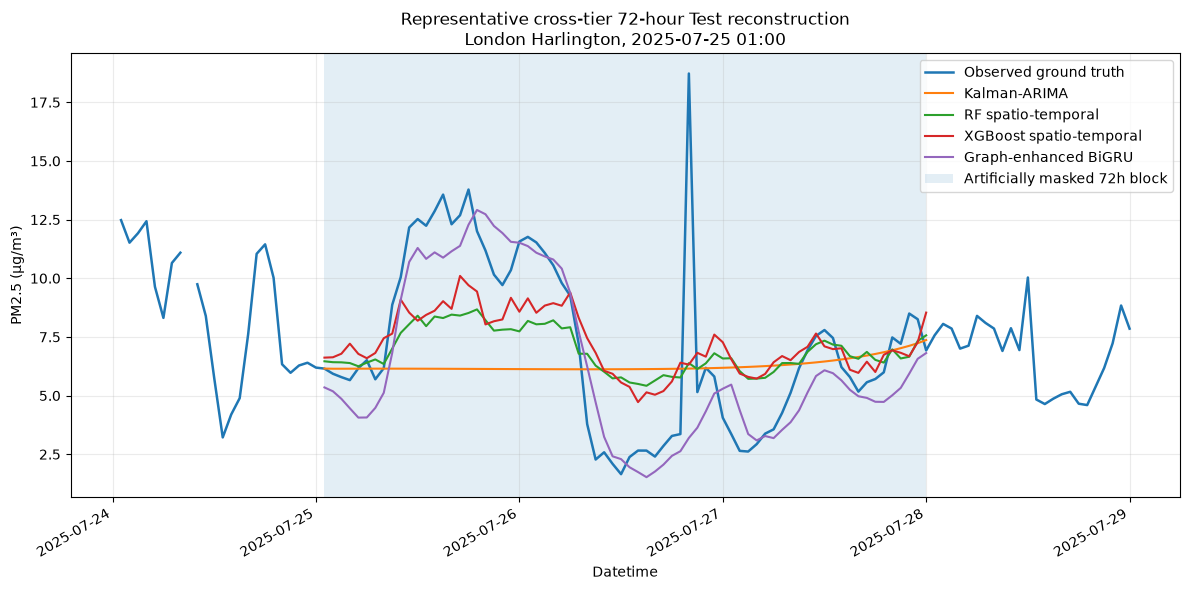

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_representative_block72_reconstruction.png


In [14]:
# ============================================================
# Step 13: Shared representative 72-hour reconstruction
# ============================================================

representative_selection = read_csv_required(
    DL_PATHS["representative_selection"],
    parse_dates=["BlockStart", "BlockEnd"],
)
if len(representative_selection) != 1:
    raise ValueError("The DL representative-block selection must contain exactly one row.")

representative_row = representative_selection.iloc[0]
representative_station = str(representative_row["Station"])
representative_start = pd.Timestamp(representative_row["BlockStart"])
representative_end = pd.Timestamp(representative_row["BlockEnd"])
context_start = representative_start - pd.Timedelta(hours=24)
context_end = representative_end + pd.Timedelta(hours=24)

base_data = pd.read_csv(
    BASE_DATA_PATH,
    usecols=["Station", "Datetime", "PM25_original"],
    parse_dates=["Datetime"],
)
actual_context = base_data.loc[
    base_data["Station"].eq(representative_station)
    & base_data["Datetime"].between(context_start, context_end)
].sort_values("Datetime")

selected_block_predictions = combined_predictions.loc[
    combined_predictions["Scenario"].eq(block_scenario)
    & combined_predictions["Station"].eq(representative_station)
    & combined_predictions["Datetime"].between(representative_start, representative_end)
    & combined_predictions["ModelID"].isin(PRIMARY_BLOCK72_MODELS)
].copy()
assert len(selected_block_predictions) == 72 * len(PRIMARY_BLOCK72_MODELS)

representative_output_df = selected_block_predictions[
    ["ModelID", "DisplayName", "Station", "Datetime", "Truth", "Prediction"]
].copy()
representative_output_df["SelectionRule"] = (
    "DL graph block MAE closest to median DL graph block MAE"
)
atomic_write_dataframe(
    representative_output_df,
    OUTPUT_DIR / "cross_tier_representative_block72_predictions.csv",
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    actual_context["Datetime"],
    actual_context["PM25_original"],
    linewidth=1.8,
    label="Observed ground truth",
)
for model_id in PRIMARY_BLOCK72_MODELS:
    model_block = selected_block_predictions.loc[
        selected_block_predictions["ModelID"].eq(model_id)
    ].sort_values("Datetime")
    ax.plot(
        model_block["Datetime"],
        model_block["Prediction"],
        label=MODEL_METADATA[model_id]["DisplayName"],
    )
ax.axvspan(
    representative_start,
    representative_end,
    alpha=0.12,
    label="Artificially masked 72h block",
)
ax.set_xlabel("Datetime")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title(
    "Representative cross-tier 72-hour Test reconstruction\n"
    f"{representative_station}, {representative_start:%Y-%m-%d %H:%M}"
)
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
representative_plot_path = FIGURE_DIR / "cross_tier_representative_block72_reconstruction.png"
fig.savefig(representative_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", representative_plot_path)

## RQ4: Accuracy–cost comparison

### Primary operational benchmark

The primary Pareto view uses the time required to apply each frozen method to the **complete five-scenario Test workload after the source data are already available in memory**.

- Statistical timing includes application of each imputation method to the Test time-series context.
- ML timing includes leakage-safe feature construction, frozen preprocessing transformation and median model inference; disk loading and model loading are excluded.
- DL timing uses the median complete five-scenario **CPU inference** time with the frozen Test tensors and centred-window loaders already constructed.

Operational inference is therefore standardised to CPU across all model families using one effective worker or PyTorch thread. Exact implementation boundaries remain different and are retained for every model.

### Costs reported separately

Model-selection time and final fitting/training time are reported separately because the model families used different, model-appropriate procedures. Statistical and ML selection/fitting used CPU implementations, while DL tuning and final training used GPU acceleration. A secondary plot adds final-fit time to the CPU operational application time.

### Runtime comparability

Each tier used one warm-up and five timed inference repeats summarised by the median. The primary operational comparison is **CPU-aligned at inference**, but it is not fully hardware-neutral or implementation-neutral because preprocessing, batching and application boundaries differ across model families.


In [15]:
# ============================================================
# Step 14: Harmonise frozen selection, fit and operational costs
# ============================================================

stat_cost = read_csv_required(STAT_PATHS["accuracy_cost"])
ml_cost = read_csv_required(ML_PATHS["accuracy_cost"])
ml_runtime_records = read_csv_required(ML_PATHS["runtime_records"])
dl_runtime = read_csv_required(DL_PATHS["runtime"])
dl_inference_timing = read_csv_required(DL_PATHS["inference_timing"])

assert stat_manifest["InferenceProtocol"]["WarmupRepeats"] == 1
assert stat_manifest["InferenceProtocol"]["TimedRepeats"] == 5
assert stat_manifest["EffectiveWorkers"] == 1
assert ml_environment["InferenceRepeats"] == 5
assert ml_environment["RuntimeEffectiveWorkers"] == 1

required_dl_inference_columns = {
    "ModelVariant",
    "InferenceDevice",
    "CPUThreads",
    "EvaluationBatchSize",
    "WarmupRuns",
    "TimedRepeats",
    "MedianFullFiveScenarioInferenceSeconds",
}
missing_dl_inference_columns = (
    required_dl_inference_columns
    - set(dl_inference_timing.columns)
)
if missing_dl_inference_columns:
    raise RuntimeError(
        "Notebook 08c CPU-inference timing columns are missing: "
        f"{sorted(missing_dl_inference_columns)}. Run the final CPU-inference "
        "version of Notebook 08c before Notebook 09."
    )

required_dl_runtime_columns = {
    "ModelVariant",
    "TrainingSeconds",
    "TrainingDevice",
    "InferenceDevice",
    "CPUInferenceThreads",
    "MedianFullFiveScenarioInferenceSeconds",
}
missing_dl_runtime_columns = (
    required_dl_runtime_columns
    - set(dl_runtime.columns)
)
if missing_dl_runtime_columns:
    raise RuntimeError(
        "Notebook 08c CPU-inference runtime columns are missing: "
        f"{sorted(missing_dl_runtime_columns)}. Run the final CPU-inference "
        "version of Notebook 08c before Notebook 09."
    )

assert dl_inference_timing["WarmupRuns"].eq(1).all()
assert dl_inference_timing["TimedRepeats"].eq(5).all()
assert dl_inference_timing["InferenceDevice"].astype(str).str.lower().eq("cpu").all()
assert dl_inference_timing["CPUThreads"].astype(int).eq(1).all()

assert dl_runtime["InferenceDevice"].astype(str).str.lower().eq("cpu").all()
assert dl_runtime["CPUInferenceThreads"].astype(int).eq(1).all()

expected_dl_variants = {"zero_neighbour", "graph_enhanced"}
assert set(dl_inference_timing["ModelVariant"]) == expected_dl_variants
assert set(dl_runtime["ModelVariant"]) == expected_dl_variants

dl_training_device = str(
    dl_manifest.get("TrainingDevice", "cuda")
)
dl_training_gpu = (
    dl_manifest.get("GPUUsedForTraining")
    or dl_manifest.get("GPU")
)

if dl_training_device.lower().startswith("cuda"):
    dl_final_fit_device = (
        f"GPU: {dl_training_gpu}"
        if dl_training_gpu
        else dl_training_device
    )
else:
    dl_final_fit_device = dl_training_device

runtime_rows = []

# Statistical operational boundary: full method application to the in-memory
# Test time-series context. The tier notebook already records the median of
# five repetitions for each scenario.
for source_model_name in stat_cost["Model"].drop_duplicates():
    model_id = normalise_statistical_model(source_model_name)
    model_cost = stat_cost.loc[
        stat_cost["Model"].eq(source_model_name)
    ].copy()
    assert set(model_cost["Scenario"]) == set(SCENARIOS)

    selection_seconds = float(
        model_cost["SelectionSeconds"].iloc[0]
    )
    final_fit_seconds = float(
        model_cost["FinalFitSeconds"].iloc[0]
    )
    operational_seconds = float(
        model_cost["MedianInferenceSeconds"].sum()
    )

    runtime_rows.append({
        "ModelID": model_id,
        "SelectionSeconds": selection_seconds,
        "SelectionApplicable": selection_seconds > 0,
        "SelectionCostAttribution": (
            "Model-specific"
            if selection_seconds > 0
            else "Not applicable"
        ),
        "FinalFitSeconds": final_fit_seconds,
        "FinalFitDevice": "CPU, one effective worker",
        "OperationalFiveScenarioSeconds": operational_seconds,
        "OperationalInferenceDevice": "CPU",
        "OperationalDeviceControlled": True,
        "FiveScenarioTargetCount": (
            EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
        ),
        "OperationalMillisecondsPer1000Targets": (
            operational_seconds
            / EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
            * 1_000_000
        ),
        "OperationalBoundary": (
            "In-memory Test time-series context to completed "
            "statistical imputation; disk loading excluded"
        ),
        "RuntimeDevice": "CPU, one effective worker",
        "RuntimeSource": (
            "Notebook 06 frozen repeated runtime outputs"
        ),
        "WarmupRuns": 1,
        "TimedRepeats": 5,
    })

# ML operational boundary: scenario feature engineering + frozen preprocessing
# transform + median inference. Model loading and all disk I/O are excluded.
for (source_model_name, feature_set), model_id in (
    ml_model_map.items()
):
    model_cost = ml_cost.loc[
        ml_cost["Model"].eq(source_model_name)
        & ml_cost["FeatureSet"].eq(feature_set)
    ].copy()
    assert set(model_cost["Scenario"]) == set(SCENARIOS)

    selection_seconds = float(
        model_cost["SelectionSeconds"].iloc[0]
    )
    final_fit_seconds = float(
        model_cost["FinalFitSeconds"].iloc[0]
    )
    scenario_operational_seconds = []

    for scenario in SCENARIOS:
        feature_rows = ml_runtime_records.loc[
            ml_runtime_records["Model"].eq(
                "SharedPipeline"
            )
            & ml_runtime_records["Scenario"].eq(scenario)
            & ml_runtime_records["FeatureSet"].eq("all")
            & ml_runtime_records["Stage"].eq(
                "feature_engineering"
            )
        ]
        transform_rows = ml_runtime_records.loc[
            ml_runtime_records["Model"].eq(
                "SharedPipeline"
            )
            & ml_runtime_records["Scenario"].eq(scenario)
            & ml_runtime_records["FeatureSet"].eq(
                feature_set
            )
            & ml_runtime_records["Stage"].eq(
                "preprocessing_transform"
            )
        ]
        inference_rows = ml_runtime_records.loc[
            ml_runtime_records["Model"].eq(
                source_model_name
            )
            & ml_runtime_records["Scenario"].eq(scenario)
            & ml_runtime_records["FeatureSet"].eq(
                feature_set
            )
            & ml_runtime_records["Stage"].eq("inference")
        ]

        if (
            len(feature_rows) != 1
            or len(transform_rows) != 1
            or len(inference_rows) != 5
        ):
            raise RuntimeError(
                "Unexpected ML operational timing rows for "
                f"{source_model_name}, {feature_set}, "
                f"{scenario}."
            )

        scenario_operational_seconds.append(
            float(
                feature_rows["ElapsedSeconds"].iloc[0]
            )
            + float(
                transform_rows["ElapsedSeconds"].iloc[0]
            )
            + float(
                inference_rows["ElapsedSeconds"].median()
            )
        )

    operational_seconds = float(
        sum(scenario_operational_seconds)
    )

    runtime_rows.append({
        "ModelID": model_id,
        "SelectionSeconds": selection_seconds,
        "SelectionApplicable": True,
        "SelectionCostAttribution": (
            "Model-feature-set-specific tuning"
        ),
        "FinalFitSeconds": final_fit_seconds,
        "FinalFitDevice": "CPU, one effective worker",
        "OperationalFiveScenarioSeconds": (
            operational_seconds
        ),
        "OperationalInferenceDevice": "CPU",
        "OperationalDeviceControlled": True,
        "FiveScenarioTargetCount": (
            EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
        ),
        "OperationalMillisecondsPer1000Targets": (
            operational_seconds
            / EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
            * 1_000_000
        ),
        "OperationalBoundary": (
            "In-memory masked panel to predictions: "
            "leakage-safe feature engineering + frozen "
            "preprocessing transform + median model inference; "
            "model loading and disk I/O excluded"
        ),
        "RuntimeDevice": "CPU, one effective worker",
        "RuntimeSource": (
            "Notebook 07 frozen stage-level repeated "
            "runtime outputs"
        ),
        "WarmupRuns": 1,
        "TimedRepeats": 5,
    })

# DL operational boundary: frozen Test tensors and centred-window loaders to
# complete five-scenario CPU prediction. Final fitting remains GPU-based.
dl_tuning_seconds = float(
    dl_tuning_manifest["OverallTuningSecondsThisSession"]
)
dl_runtime_model_map = {
    "zero_neighbour": "dl_zero_neighbour",
    "graph_enhanced": "dl_graph_enhanced",
}

for variant_name, model_id in (
    dl_runtime_model_map.items()
):
    model_runtime = dl_runtime.loc[
        dl_runtime["ModelVariant"].eq(variant_name)
    ]
    inference_row = dl_inference_timing.loc[
        dl_inference_timing[
            "ModelVariant"
        ].eq(variant_name)
    ]

    if len(model_runtime) != 1:
        raise ValueError(
            "Expected exactly one DL runtime row for "
            f"{variant_name}."
        )
    if len(inference_row) != 1:
        raise ValueError(
            "Expected exactly one DL inference-timing row for "
            f"{variant_name}."
        )

    model_runtime = model_runtime.iloc[0]
    inference_row = inference_row.iloc[0]

    assert str(
        model_runtime["InferenceDevice"]
    ).lower() == "cpu"
    assert int(
        model_runtime["CPUInferenceThreads"]
    ) == 1
    assert str(
        inference_row["InferenceDevice"]
    ).lower() == "cpu"
    assert int(
        inference_row["CPUThreads"]
    ) == 1

    runtime_median = float(
        model_runtime[
            "MedianFullFiveScenarioInferenceSeconds"
        ]
    )
    timing_median = float(
        inference_row[
            "MedianFullFiveScenarioInferenceSeconds"
        ]
    )
    if not np.isclose(
        runtime_median,
        timing_median,
        rtol=0.0,
        atol=1e-12,
    ):
        raise RuntimeError(
            "DL runtime summary and repeated CPU inference "
            f"timing disagree for {variant_name}."
        )

    selection_applicable = (
        variant_name == "graph_enhanced"
    )
    selection_seconds = (
        dl_tuning_seconds
        if selection_applicable
        else 0.0
    )

    runtime_rows.append({
        "ModelID": model_id,
        "SelectionSeconds": float(
            selection_seconds
        ),
        "SelectionApplicable": (
            selection_applicable
        ),
        "SelectionCostAttribution": (
            "Graph-model tuning"
            if selection_applicable
            else (
                "Inherited frozen graph configuration; "
                "zero-neighbour control not retuned"
            )
        ),
        "FinalFitSeconds": float(
            model_runtime["TrainingSeconds"]
        ),
        "FinalFitDevice": dl_final_fit_device,
        "OperationalFiveScenarioSeconds": (
            timing_median
        ),
        "OperationalInferenceDevice": "CPU",
        "OperationalDeviceControlled": True,
        "FiveScenarioTargetCount": (
            EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
        ),
        "OperationalMillisecondsPer1000Targets": (
            timing_median
            / EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
            * 1_000_000
        ),
        "OperationalBoundary": (
            "Frozen in-memory Test tensors and centred-window "
            "loaders to complete five-scenario CPU predictions; "
            "disk I/O excluded"
        ),
        "RuntimeDevice": "CPU, one PyTorch thread",
        "RuntimeSource": (
            "Notebook 08c frozen CPU inference and GPU "
            "final-fit outputs"
        ),
        "WarmupRuns": int(
            inference_row["WarmupRuns"]
        ),
        "TimedRepeats": int(
            inference_row["TimedRepeats"]
        ),
    })

runtime_summary_df = attach_model_metadata(
    pd.DataFrame(runtime_rows)
)
runtime_summary_df[
    "FinalFitPlusOperationalSeconds"
] = (
    runtime_summary_df["FinalFitSeconds"]
    + runtime_summary_df[
        "OperationalFiveScenarioSeconds"
    ]
)
runtime_summary_df[
    "SelectionPlusFitPlusOperationalSeconds"
] = (
    runtime_summary_df["SelectionSeconds"]
    + runtime_summary_df[
        "FinalFitPlusOperationalSeconds"
    ]
)

assert set(runtime_summary_df["ModelID"]) == set(
    MODEL_ORDER
)
assert runtime_summary_df[
    "FiveScenarioTargetCount"
].eq(
    EXPECTED_TOTAL_FIVE_SCENARIO_TARGETS
).all()
assert runtime_summary_df[
    "WarmupRuns"
].eq(1).all()
assert runtime_summary_df[
    "TimedRepeats"
].eq(5).all()
assert runtime_summary_df[
    "OperationalInferenceDevice"
].eq("CPU").all()
assert runtime_summary_df[
    "OperationalDeviceControlled"
].all()
assert runtime_summary_df[
    "RuntimeDevice"
].str.startswith("CPU").all()

accuracy_cost_summary_df = (
    family_metrics_df.merge(
        runtime_summary_df,
        on=[
            "ModelID",
            "DisplayName",
            "ShortLabel",
            "ModelFamily",
            "SpatialSetting",
        ],
        how="inner",
        validate="one_to_one",
    )
)

atomic_write_dataframe(
    runtime_summary_df,
    OUTPUT_DIR
    / "cross_tier_runtime_summary.csv",
)
atomic_write_dataframe(
    accuracy_cost_summary_df,
    OUTPUT_DIR
    / "cross_tier_accuracy_cost_summary.csv",
)

display(
    accuracy_cost_summary_df[
        [
            "DisplayName",
            "FinalFitDevice",
            "RuntimeDevice",
            "OperationalBoundary",
            "SelectionSeconds",
            "FinalFitSeconds",
            "OperationalFiveScenarioSeconds",
            "OperationalMillisecondsPer1000Targets",
            "FinalFitPlusOperationalSeconds",
            "FamilyBalancedMAE",
        ]
    ].sort_values("FamilyBalancedMAE")
)


,DisplayName,FinalFitDevice,RuntimeDevice,OperationalBoundary,SelectionSeconds,FinalFitSeconds,OperationalFiveScenarioSeconds,OperationalMillisecondsPer1000Targets,FinalFitPlusOperationalSeconds,FamilyBalancedMAE
0,Graph-enhanced BiGRU,GPU: NVIDIA GeForce GTX 1660 Ti,"CPU, one PyTorch thread",Frozen in-memory Test tensors and centred-wind...,"6,631.088704",179.787888,56.501251,"1,182.281873",236.289139,1.395686
1,Linear interpolation,"CPU, one effective worker","CPU, one effective worker",In-memory Test time-series context to complete...,0.000000,0.000000,0.142526,2.982346,0.142526,2.281357
2,Kalman-ARIMA,"CPU, one effective worker","CPU, one effective worker",In-memory Test time-series context to complete...,331.694521,53.538072,2.203691,46.111967,55.741763,2.303559
3,BiGRU zero-neighbour control,GPU: NVIDIA GeForce GTX 1660 Ti,"CPU, one PyTorch thread",Frozen in-memory Test tensors and centred-wind...,0.000000,178.878931,56.348156,"1,179.078393",235.227087,2.325186
4,XGBoost spatio-temporal,"CPU, one effective worker","CPU, one effective worker",In-memory masked panel to predictions: leakage...,364.332211,9.235147,6.607685,138.265020,15.842833,2.514908
5,RF spatio-temporal,"CPU, one effective worker","CPU, one effective worker",In-memory masked panel to predictions: leakage...,"1,421.039912",110.801382,7.766289,162.508655,118.567670,2.644987
6,XGBoost non-spatial,"CPU, one effective worker","CPU, one effective worker",In-memory masked panel to predictions: leakage...,255.662927,6.884293,6.563525,137.340967,13.447818,3.014731
7,RF non-spatial,"CPU, one effective worker","CPU, one effective worker",In-memory masked panel to predictions: leakage...,"1,211.225742",256.410368,9.309052,194.790797,265.719420,3.194881
8,Station train mean,"CPU, one effective worker","CPU, one effective worker",In-memory Test time-series context to complete...,0.000000,0.026447,0.023417,0.489990,0.049864,5.332880


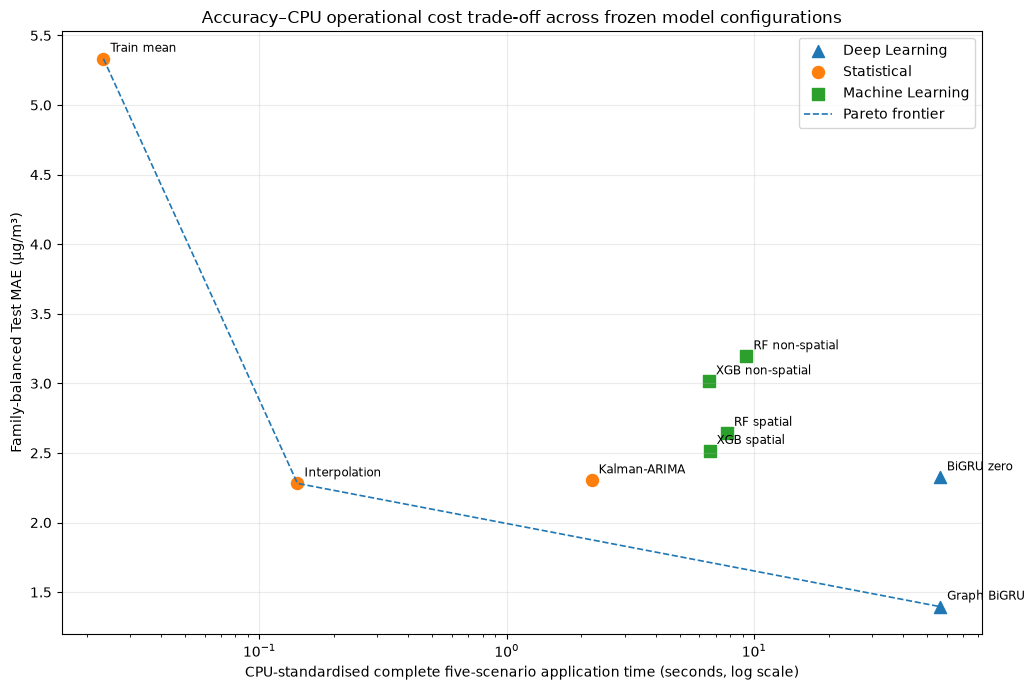

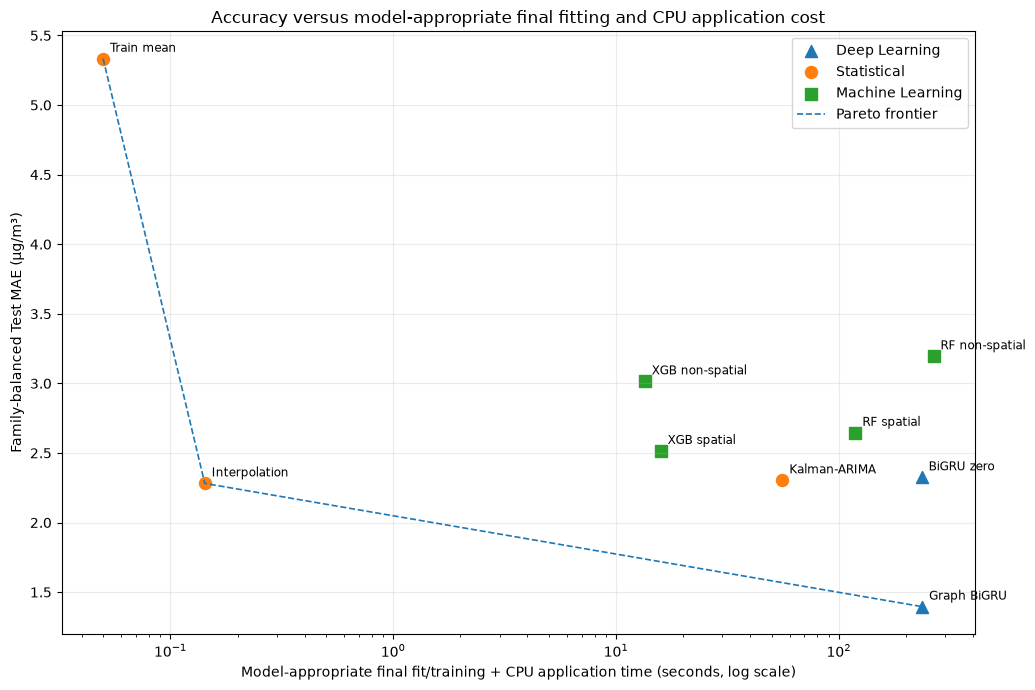

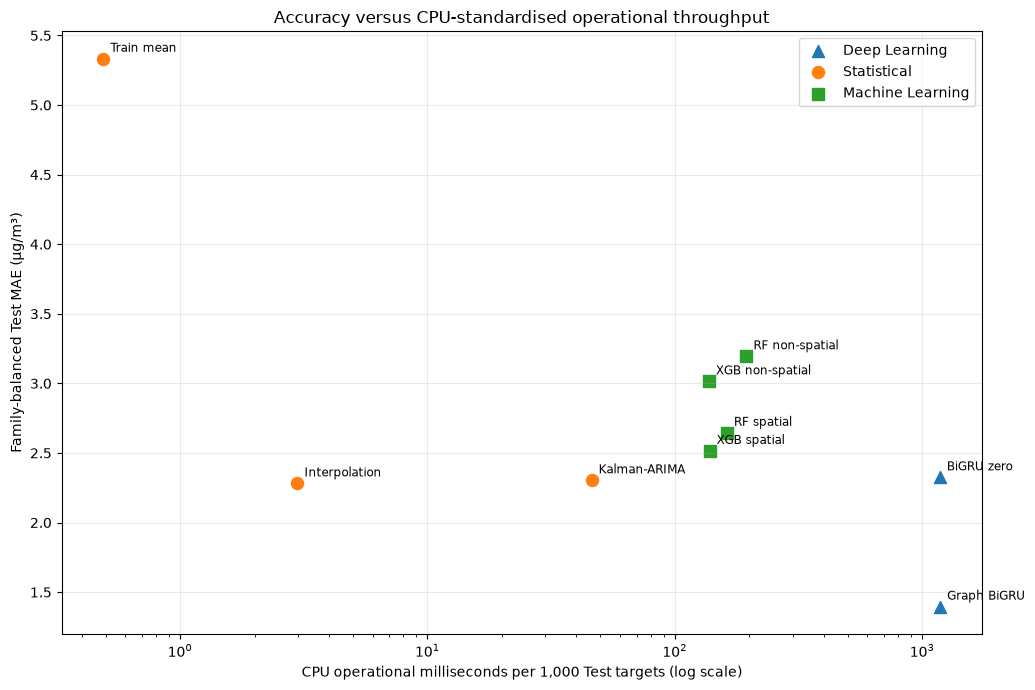

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_accuracy_cost_pareto.png
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_fit_plus_application_pareto.png
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_inference_throughput_pareto.png
Primary operational Pareto frontier:


,DisplayName,FinalFitDevice,RuntimeDevice,OperationalBoundary,FamilyBalancedMAE,OperationalFiveScenarioSeconds
8,Station train mean,"CPU, one effective worker","CPU, one effective worker",In-memory Test time-series context to complete...,5.332880,0.023417
1,Linear interpolation,"CPU, one effective worker","CPU, one effective worker",In-memory Test time-series context to complete...,2.281357,0.142526
0,Graph-enhanced BiGRU,GPU: NVIDIA GeForce GTX 1660 Ti,"CPU, one PyTorch thread",Frozen in-memory Test tensors and centred-wind...,1.395686,56.501251


In [16]:
# ============================================================
# Step 15: Pareto-frontier calculations and RQ4 figures
# ============================================================

def pareto_frontier_mask(x_values: np.ndarray, y_values: np.ndarray) -> np.ndarray:
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    frontier = np.ones(len(x_values), dtype=bool)

    for index in range(len(x_values)):
        dominated = (
            (x_values <= x_values[index])
            & (y_values <= y_values[index])
            & ((x_values < x_values[index]) | (y_values < y_values[index]))
        )
        if dominated.any():
            frontier[index] = False

    return frontier


accuracy_cost_summary_df["OnOperationalParetoFrontier"] = pareto_frontier_mask(
    accuracy_cost_summary_df["OperationalFiveScenarioSeconds"],
    accuracy_cost_summary_df["FamilyBalancedMAE"],
)
accuracy_cost_summary_df["OnFitPlusOperationalParetoFrontier"] = pareto_frontier_mask(
    accuracy_cost_summary_df["FinalFitPlusOperationalSeconds"],
    accuracy_cost_summary_df["FamilyBalancedMAE"],
)
atomic_write_dataframe(
    accuracy_cost_summary_df,
    OUTPUT_DIR / "cross_tier_accuracy_cost_summary.csv",
)

family_markers = {
    "Statistical": "o",
    "Machine Learning": "s",
    "Deep Learning": "^",
}

# Primary RQ4 figure: harmonised operational application boundary.
fig, ax = plt.subplots(figsize=(10.5, 7))
for family_name, family_df in accuracy_cost_summary_df.groupby("ModelFamily", sort=False):
    ax.scatter(
        family_df["OperationalFiveScenarioSeconds"],
        family_df["FamilyBalancedMAE"],
        marker=family_markers[family_name],
        s=75,
        label=family_name,
    )
for row in accuracy_cost_summary_df.itertuples(index=False):
    ax.annotate(
        row.ShortLabel,
        (row.OperationalFiveScenarioSeconds, row.FamilyBalancedMAE),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8.5,
    )
frontier_df = accuracy_cost_summary_df.loc[
    accuracy_cost_summary_df["OnOperationalParetoFrontier"]
].sort_values("OperationalFiveScenarioSeconds")
if len(frontier_df) > 1:
    ax.plot(
        frontier_df["OperationalFiveScenarioSeconds"],
        frontier_df["FamilyBalancedMAE"],
        linestyle="--",
        linewidth=1.2,
        label="Pareto frontier",
    )
ax.set_xscale("log")
ax.set_xlabel("CPU-standardised complete five-scenario application time (seconds, log scale)")
ax.set_ylabel("Family-balanced Test MAE (µg/m³)")
ax.set_title("Accuracy–CPU operational cost trade-off across frozen model configurations")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
pareto_plot_path = FIGURE_DIR / "cross_tier_accuracy_cost_pareto.png"
fig.savefig(pareto_plot_path, dpi=300, bbox_inches="tight")
plt.show()

# Secondary view: final fitting/training plus operational application.
fig, ax = plt.subplots(figsize=(10.5, 7))
for family_name, family_df in accuracy_cost_summary_df.groupby("ModelFamily", sort=False):
    ax.scatter(
        family_df["FinalFitPlusOperationalSeconds"],
        family_df["FamilyBalancedMAE"],
        marker=family_markers[family_name],
        s=75,
        label=family_name,
    )
for row in accuracy_cost_summary_df.itertuples(index=False):
    ax.annotate(
        row.ShortLabel,
        (row.FinalFitPlusOperationalSeconds, row.FamilyBalancedMAE),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8.5,
    )
fit_frontier_df = accuracy_cost_summary_df.loc[
    accuracy_cost_summary_df["OnFitPlusOperationalParetoFrontier"]
].sort_values("FinalFitPlusOperationalSeconds")
if len(fit_frontier_df) > 1:
    ax.plot(
        fit_frontier_df["FinalFitPlusOperationalSeconds"],
        fit_frontier_df["FamilyBalancedMAE"],
        linestyle="--",
        linewidth=1.2,
        label="Pareto frontier",
    )
ax.set_xscale("log")
ax.set_xlabel("Model-appropriate final fit/training + CPU application time (seconds, log scale)")
ax.set_ylabel("Family-balanced Test MAE (µg/m³)")
ax.set_title("Accuracy versus model-appropriate final fitting and CPU application cost")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fit_plus_pareto_path = FIGURE_DIR / "cross_tier_fit_plus_application_pareto.png"
fig.savefig(fit_plus_pareto_path, dpi=300, bbox_inches="tight")
plt.show()

# Normalised operational throughput view.
fig, ax = plt.subplots(figsize=(10.5, 7))
for family_name, family_df in accuracy_cost_summary_df.groupby("ModelFamily", sort=False):
    ax.scatter(
        family_df["OperationalMillisecondsPer1000Targets"],
        family_df["FamilyBalancedMAE"],
        marker=family_markers[family_name],
        s=75,
        label=family_name,
    )
for row in accuracy_cost_summary_df.itertuples(index=False):
    ax.annotate(
        row.ShortLabel,
        (row.OperationalMillisecondsPer1000Targets, row.FamilyBalancedMAE),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8.5,
    )
ax.set_xscale("log")
ax.set_xlabel("CPU operational milliseconds per 1,000 Test targets (log scale)")
ax.set_ylabel("Family-balanced Test MAE (µg/m³)")
ax.set_title("Accuracy versus CPU-standardised operational throughput")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
inference_pareto_path = FIGURE_DIR / "cross_tier_inference_throughput_pareto.png"
fig.savefig(inference_pareto_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", pareto_plot_path)
print("Saved:", fit_plus_pareto_path)
print("Saved:", inference_pareto_path)
print("Primary operational Pareto frontier:")
display(
    accuracy_cost_summary_df.loc[
        accuracy_cost_summary_df["OnOperationalParetoFrontier"],
        [
            "DisplayName",
            "FinalFitDevice",
            "RuntimeDevice",
            "OperationalBoundary",
            "FamilyBalancedMAE",
            "OperationalFiveScenarioSeconds",
        ],
    ].sort_values("OperationalFiveScenarioSeconds")
)

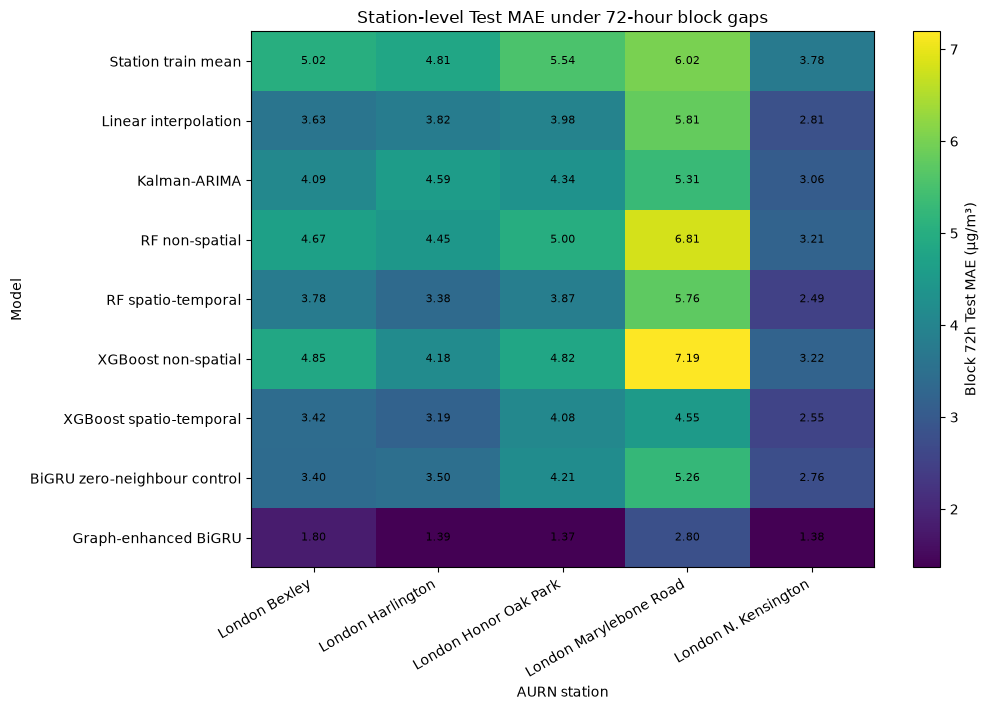

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\figures\cross_tier_block72_station_mae_heatmap.png


In [17]:
# ============================================================
# Step 16: Station-level Test metrics and Appendix heatmap
# ============================================================

station_metric_rows = []
for (model_id, scenario, station), group in combined_predictions.groupby(
    ["ModelID", "Scenario", "Station"], sort=True
):
    metrics = calculate_regression_metrics(group["Truth"], group["Prediction"])
    station_metric_rows.append({
        "ModelID": model_id,
        "Scenario": scenario,
        "Station": station,
        **metrics,
    })
station_metrics_df = attach_model_metadata(pd.DataFrame(station_metric_rows))
atomic_write_dataframe(
    station_metrics_df,
    OUTPUT_DIR / "cross_tier_test_metrics_by_station.csv",
)

block72_station_matrix = station_metrics_df.loc[
    station_metrics_df["Scenario"].eq("block72_10percent")
].pivot(index="ModelID", columns="Station", values="MAE").reindex(index=MODEL_ORDER)

fig, ax = plt.subplots(figsize=(10.5, 7.2))
image = ax.imshow(block72_station_matrix.to_numpy(), aspect="auto")
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Block 72h Test MAE (µg/m³)")
ax.set_xticks(
    np.arange(len(block72_station_matrix.columns)),
    labels=block72_station_matrix.columns,
    rotation=30,
    ha="right",
)
ax.set_yticks(
    np.arange(len(MODEL_ORDER)),
    labels=[MODEL_METADATA[model_id]["DisplayName"] for model_id in MODEL_ORDER],
)
for row_index in range(len(MODEL_ORDER)):
    for column_index in range(len(block72_station_matrix.columns)):
        cell_value = float(block72_station_matrix.iloc[row_index, column_index])
        ax.text(
            column_index,
            row_index,
            f"{cell_value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
        )
ax.set_xlabel("AURN station")
ax.set_ylabel("Model")
ax.set_title("Station-level Test MAE under 72-hour block gaps")
fig.tight_layout()
station_heatmap_path = FIGURE_DIR / "cross_tier_block72_station_mae_heatmap.png"
fig.savefig(station_heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", station_heatmap_path)

In [18]:
# ============================================================
# Step 17: Structured RQ summaries and final immutable manifest
# ============================================================

best_family_balanced_row = family_metrics_df.sort_values("FamilyBalancedMAE").iloc[0]

rq_summary = {
    "RQ1": {
        "Question": "Accuracy across statistical, ML and DL approaches",
        "FamilyBalancedBestModel": best_family_balanced_row["DisplayName"],
        "FamilyBalancedBestMAE": float(best_family_balanced_row["FamilyBalancedMAE"]),
        "ScenarioWinners": scenario_winners_df[
            ["Scenario", "WinningModel", "WinningMAE"]
        ].to_dict("records"),
    },
    "RQ2": {
        "Question": "Performance across point and block missingness",
        "ScenarioDifficultyByMedianMAE": scenario_difficulty_df[
            ["Scenario", "MedianModelMAE", "DifficultyRankByMedianMAE"]
        ].to_dict("records"),
        "Block72EdgeMiddleDiagnostics": edge_middle_df.to_dict("records"),
    },
    "RQ3": {
        "Question": "Contribution of neighbouring-station information",
        "SpatialGainDefinition": "non-spatial MAE minus spatio-temporal MAE",
        "FamilySpatialGain": family_spatial_gain_df.to_dict("records"),
        "DesignDifference": (
            "ML feature sets were tuned separately; DL used a controlled zero-neighbour ablation"
        ),
    },
    "RQ4": {
        "Question": "Accuracy versus computational cost",
        "PrimaryCostDefinition": (
            "CPU-standardised operational application time for the complete five-scenario Test workload"
        ),
        "ParetoFrontierModels": accuracy_cost_summary_df.loc[
            accuracy_cost_summary_df["OnOperationalParetoFrontier"],
            [
                "DisplayName",
                "RuntimeDevice",
                "FamilyBalancedMAE",
                "OperationalFiveScenarioSeconds",
            ],
        ].to_dict("records"),
        "RuntimeCaveat": (
            "Operational inference used CPU execution with one effective worker "
            "or PyTorch thread across all model families. Selection and final "
            "fitting remained device-aware and model-family appropriate. "
            "The comparison is not fully implementation-neutral because "
            "preprocessing, batching and application boundaries differ."
        ),
    },
}

rq_summary_path = OUTPUT_DIR / "cross_tier_rq_summary.json"
atomic_write_json(rq_summary, rq_summary_path)

required_output_paths = [
    OUTPUT_DIR / "cross_tier_source_file_audit.csv",
    unified_predictions_path,
    OUTPUT_DIR / "cross_tier_test_target_key_audit.csv",
    OUTPUT_DIR / "cross_tier_metric_reproduction_audit.csv",
    OUTPUT_DIR / "cross_tier_test_metrics.csv",
    OUTPUT_DIR / "cross_tier_family_balanced_metrics.csv",
    OUTPUT_DIR / "cross_tier_scenario_rankings.csv",
    OUTPUT_DIR / "cross_tier_scenario_winners.csv",
    OUTPUT_DIR / "cross_tier_scenario_difficulty_summary.csv",
    OUTPUT_DIR / "cross_tier_spatial_gain_by_scenario.csv",
    OUTPUT_DIR / "cross_tier_spatial_gain_by_family.csv",
    OUTPUT_DIR / "cross_tier_block72_position_metrics.csv",
    OUTPUT_DIR / "cross_tier_block72_edge_middle_summary.csv",
    OUTPUT_DIR / "cross_tier_representative_block72_predictions.csv",
    OUTPUT_DIR / "cross_tier_runtime_summary.csv",
    OUTPUT_DIR / "cross_tier_accuracy_cost_summary.csv",
    OUTPUT_DIR / "cross_tier_test_metrics_by_station.csv",
    rq_summary_path,
    mae_heatmap_path,
    family_bar_path,
    spatial_gain_plot_path,
    block_position_plot_path,
    representative_plot_path,
    pareto_plot_path,
    fit_plus_pareto_path,
    inference_pareto_path,
    station_heatmap_path,
]
for path in required_output_paths:
    if not path.exists():
        raise FileNotFoundError(f"Required Notebook 09 output is missing: {path}")

manifest = {
    "Status": "comparison_complete",
    "ComparisonVersion": COMPARISON_VERSION,
    "Notebook": "09_cross_tier_final_comparison_and_accuracy_cost_benchmark",
    "DocumentedRerunReason": DOCUMENTED_RERUN_REASON,
    "NoModelTuningOrRefitting": True,
    "EvaluationSplit": "Test",
    "Scenarios": SCENARIOS,
    "ExpectedTestTargetCounts": EXPECTED_TEST_TARGET_COUNTS,
    "Models": MODEL_ORDER,
    "ModelMetadata": MODEL_METADATA,
    "ExpectedModelScenarioEvaluations": 45,
    "ObservedModelScenarioEvaluations": int(len(unified_metrics_df)),
    "TargetRowAuditPassed": bool(
        target_key_audit_df[["KeysMatchReference", "TruthMatchesReference"]].all().all()
    ),
    "MetricReproductionAuditPassed": bool(
        source_metric_audit_df["AllMetricsReproduced"].all()
    ),
    "SpatialGainDefinition": "DeltaMAE = non-spatial MAE - spatio-temporal MAE",
    "RuntimeProtocol": {
        "WarmupRuns": 1,
        "TimedInferenceRepeats": 5,
        "SummaryStatistic": "median",
        "DiskIOIncluded": False,
        "OperationalInferenceDeviceControlled": True,
        "OperationalInferenceDevice": "CPU",
        "CPUWorkersOrThreads": 1,
        "PrimaryCostMeasure": (
            "CPU-standardised complete five-scenario operational "
            "application seconds"
        ),
        "SelectionCostReportedSeparately": True,
        "SelectionAndFinalFitDeviceAware": True,
        "DLSelectionAndFinalFitDevice": dl_final_fit_device,
        "HardwareNeutralComparison": False,
        "ImplementationNeutralComparison": False,
        "IdenticalOperationalBoundariesAcrossFamilies": False,
    },
    "SourceFiles": source_file_audit_df.to_dict("records"),
    "OutputFiles": [
        {
            "Path": str(path),
            "Bytes": int(path.stat().st_size),
            "SHA256": file_sha256(path),
        }
        for path in required_output_paths
    ],
    "Environment": {
        "PythonVersion": sys.version.split()[0],
        "Platform": platform.platform(),
        "PandasVersion": pd.__version__,
        "NumPyVersion": np.__version__,
    },
}
atomic_write_json(manifest, FINAL_MANIFEST_PATH)
assert FINAL_MANIFEST_PATH.exists()

print("Cross-tier Test target audit passed.")
print("Cross-tier metric reproduction audit passed.")
print("Unified RQ1–RQ4 comparison outputs saved with CPU-standardised operational inference.")
print("Manifest:", FINAL_MANIFEST_PATH)
print(
    "\nNOTEBOOK 09 COMPLETE.\n"
    "Do not use these Test results to retune or alter any statistical, ML or DL model."
)

Cross-tier Test target audit passed.
Cross-tier metric reproduction audit passed.
Unified RQ1–RQ4 comparison outputs saved with CPU-standardised operational inference.
Manifest: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\final_comparison\09_cross_tier\cross_tier_comparison_manifest.json

NOTEBOOK 09 COMPLETE.
Do not use these Test results to retune or alter any statistical, ML or DL model.


## Dissertation-use guidance

### Main Results figures

The strongest main-body figures produced by Notebook 10 are:

1. `cross_tier_test_mae_heatmap.png` for RQ1 and RQ2;
2. `cross_tier_spatial_gain_delta_mae.png` for RQ3;
3. `cross_tier_accuracy_cost_pareto.png` for RQ4;
4. `cross_tier_block72_position_mae.png` for long-gap behaviour.

### Main text or Appendix

`cross_tier_representative_block72_reconstruction.png` is recommended for the main text if space permits; otherwise place it in the Appendix.

### Appendix-ready diagnostics

- family-balanced MAE bar chart;
- final-fit-plus-application Pareto plot;
- CPU-normalised operational-throughput plot;
- Block 72h station-level heatmap;
- complete scenario rankings;
- target-key and metric-reproduction audits.

### Reporting restrictions

- Describe the primary runtime plot as **CPU-standardised operational inference**, not as a fully hardware-neutral or implementation-neutral algorithmic benchmark.
- State that statistical and ML selection/fitting used CPU, while DL tuning and final training used GPU acceleration.
- Do not infer that DL's block-gap advantage is caused solely by graph structure or solely by masked-reconstruction training.
- Do not interpret the ML feature-set comparisons as strict single-component ablations.
- Report graph contribution using the controlled zero-neighbour DL comparison.
- Do not retune any model after reviewing the unified Test results.
